# 03 — Error analysis of the final results

Comparison figures, robustness / gate / attention figures and the error analysis of the
final test and held-out runs. The interpretation is in the report (Ch. 4); the short notes
under each figure here are its raw material.

- **Nothing is simulated here.** Test and held-out results are read from the logs saved in
  `results/final/`; the flow files are read only to join each vehicle's route. The τ sweep is run by
  `scripts/tau_sweep.py` on validation and only *read* here; the attention check is in
  `04_gate_attention.ipynb`.
- Nothing is selected or changed because of what is found here: the locked models, the test
  tables and the hypothesis verdicts stay as they are.
- Differences are called *clear* only when the 95 % CI (Student t, 5 seeds) excludes 0;
  otherwise *level*. Attention weights, σ and gate statistics are associations, not causes.

Run: `jupyter nbconvert --to notebook --execute --inplace notebooks/03_error_analysis.ipynb`
(from the repo root; needs `results/final/`, about one minute). Figures are written to
`docs/figures/results/` (PNG + PDF), tables to `docs/results/`.

## 0  Set-up and reproduction checks

In [1]:
%matplotlib inline
import json
import re
import warnings
from collections.abc import Mapping, Sequence
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

from trafficrl.data.splits import REPO_ROOT
from trafficrl.eval.hypotheses import regret_summary, regret_table
from trafficrl.eval.report import condition_name, finished_run
from trafficrl.utils.plotting import (
    BLUE, BLUE_RAMP, CONTROLLER_COLOR, CONTROLLER_LABEL, INK, INK_SECONDARY, MUTED, ORANGE,
    SURFACE, VIOLET, apply_style,
)
from trafficrl.utils.stats import summarise

pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 2)
warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")

In [2]:
def job_run(study_dir: str | Path, model: str, condition: str) -> Path:
    """Run directory of one finished ``<model>__<condition>`` job of a study."""
    run = finished_run(Path(study_dir) / "eval" / f"{model}__{condition}")
    if run is None:
        raise FileNotFoundError(f"no finished run for {model}__{condition} in {study_dir}")
    return run


def read_log(run: str | Path, kind: str, seed: int) -> pd.DataFrame:
    """One per-seed log (``kind`` = ``trace``, ``vehicles`` or ``decisions``)."""
    f = Path(run) / f"{kind}_s{seed}.csv"
    if not f.exists():
        raise FileNotFoundError(f"{f} does not exist (was the run logged with this option?)")
    return pd.read_csv(f)


def load_flow(path: str | Path) -> list[dict]:
    """Flow entries of one flow file."""
    return json.loads(Path(path).read_text())


def study_runs(spec: Mapping, study_dir: Path) -> dict[tuple[str, str], Path | None]:
    """``{(model, condition): run directory or None}`` in the spec's table order."""
    return {
        (model, condition_name(dict(c or {}))): finished_run(
            Path(study_dir) / "eval" / f"{model}__{condition_name(dict(c or {}))}"
        )
        for model in spec["models"]
        for c in spec["conditions"]
    }


def load_study(spec: Mapping, study_dir: Path) -> pd.DataFrame:
    """Per-seed metrics of every finished job: ``model, condition, run_dir, seed, <metrics>``."""
    frames, absent = [], []
    for (model, cond), run in study_runs(spec, study_dir).items():
        if run is None:
            absent.append(f"{model}__{cond}")
            continue
        m = pd.read_csv(run / "metrics.csv")
        m.insert(0, "run_dir", str(run))
        m.insert(0, "condition", cond)
        m.insert(0, "model", model)
        frames.append(m)
    if absent:
        raise FileNotFoundError(f"no finished run for {absent} in {study_dir}")
    return pd.concat(frames, ignore_index=True)


class Study:
    """Per-seed metrics and lazily read logs of one finished model × condition study."""

    def __init__(self, spec: Mapping, study_dir: str | Path) -> None:
        self.spec, self.dir = dict(spec), Path(study_dir)
        self.metrics = load_study(self.spec, self.dir)
        self.seeds = [int(s) for s in self.spec["seeds"]]
        self.models = list(self.spec["models"])
        self.conditions = list(dict.fromkeys(self.metrics["condition"]))
        self._logs: dict[tuple, pd.DataFrame] = {}

    def run(self, model: str, condition: str) -> Path:
        return job_run(self.dir, model, condition)

    def log(self, model: str, condition: str, kind: str, seed: int) -> pd.DataFrame:
        key = (model, condition, kind, seed)
        if key not in self._logs:
            self._logs[key] = read_log(self.run(model, condition), kind, seed)
        return self._logs[key]

    def values(self, model: str, condition: str, metric: str) -> list[float]:
        m = self.metrics
        sel = m[(m["model"] == model) & (m["condition"] == condition)].sort_values("seed")
        return sel[metric].astype(float).tolist()

    def stats(self, model: str, condition: str, metric: str) -> dict:
        return summarise(self.values(model, condition, metric))

    def each_seed(self, model: str, condition: str, kind: str, fn) -> pd.DataFrame:
        frames = []
        for s in self.seeds:
            out = fn(self.log(model, condition, kind, s)).copy()
            out.insert(0, "seed", s)
            out.insert(0, "condition", condition)
            out.insert(0, "model", model)
            frames.append(out)
        return pd.concat(frames, ignore_index=True)


class Context:
    """Config, the two finished studies and the flow files."""

    def __init__(self, config_path: str | Path, root: str | Path | None = None) -> None:
        from trafficrl.data.splits import REPO_ROOT, flow_files
        from trafficrl.utils.config import read_yaml

        self.root = Path(root) if root is not None else REPO_ROOT
        self.cfg = read_yaml(self.root / config_path)
        final = self.root / self.cfg["final_dir"]
        self.studies: dict[str, Study] = {}
        self.flows: dict[str, dict[str, list[dict]]] = {}
        for name, s in self.cfg["studies"].items():
            spec = read_yaml(self.root / s["spec"])
            self.studies[name] = Study(spec, final / spec["study"])
            _, files = flow_files(spec["dataset"], spec["split"])
            conds = self.studies[name].conditions
            if len(files) == 1:
                self.flows[name] = {c: load_flow(files[0]) for c in conds if "surge" not in c}
            else:
                self.flows[name] = {c: load_flow(f) for c, f in zip(conds, files, strict=True)}
        self.test, self.heldout = self.studies["test"], self.studies["heldout"]
        self.figures = self.root / self.cfg["out_figures"]
        self.tables = self.root / self.cfg["out_tables"]

    def table(self, key: str) -> pd.DataFrame | None:
        """A results CSV, or None if it does not exist yet."""
        f = self.root / self.cfg[key]
        return pd.read_csv(f) if f.exists() else None

In [3]:
ctx = Context("configs/analysis.yaml")
cfg, test, held = ctx.cfg, ctx.test, ctx.heldout
AGENTS, ABLATIONS = cfg["agents"], cfg["ablations"]
PROPOSED, BASELINES, PAIRED = cfg["proposed"], cfg["baselines"], cfg["paired"]
CONDS = cfg["compare_conditions"]
print("test study   :", test.dir.relative_to(REPO_ROOT), "| models", len(test.models), "| conditions", test.conditions)
print("held-out     :", held.dir.relative_to(REPO_ROOT), "| models", len(held.models), "| flows", held.conditions)
print("seeds        :", test.seeds)

test study   : results/final/final_test | models 8 | conditions ['clean', 'noise0.1', 'noise0.2', 'drop0.1', 'drop0.2', 'surge1.5']
held-out     : results/final/final_heldout | models 7 | flows ['real', 'real_5734', 'real_5816']
seeds        : [0, 1, 2, 3, 4]


**Reproduction check.** Before any breakdown is trusted, travel time and queue are recomputed
from the per-vehicle logs and the traces for *every* model and condition of the test study
(except the surge flow, see below) and compared with `metrics.csv`. The cell stops with an
error if any episode is off by more than 0.001.

In [4]:
HORIZON_S = 3600


APPROACHES = ("E", "N", "W", "S")


LANES_PER_APPROACH = 3


_VEHICLE_ID = re.compile(r"^flow_(\d+)_(\d+)$")


def window_table(trips_: pd.DataFrame, width: int = 600, horizon: int = HORIZON_S) -> pd.DataFrame:
    """Per window of the scheduled start time (``start_time``; ``enter_t`` for frames from
    :func:`vehicle_times`): vehicles, mean travel time, mean wait, share completed."""
    v = trips_.copy()
    t0 = v["start_time"] if "start_time" in v else v["enter_t"]
    v["window"] = (np.minimum(t0, horizon - 1) // width).astype(int)
    out = (
        v.groupby("window")
        .agg(
            vehicles=("travel_s", "size"),
            travel_s=("travel_s", "mean"),
            wait_s=("wait_s", "mean"),
            completed=("completed", "mean"),
        )
        .reset_index()
    )
    out.insert(1, "start_min", out["window"] * width // 60)
    return out


def _lane_columns(trace: pd.DataFrame, prefix: str = "q_") -> list[str]:
    cols = [c for c in trace.columns if c.startswith(prefix) and c[len(prefix) :].isdigit()]
    return sorted(cols, key=lambda c: int(c[len(prefix) :]))


def step_lengths(trace: pd.DataFrame, horizon: int = HORIZON_S) -> pd.Series:
    """Seconds each row's state is held: time to the next env step (the last one runs to the
    horizon). Indexed like ``trace``."""
    times = np.sort(trace["t"].unique())
    nxt = dict(zip(times, np.append(times[1:], horizon), strict=True))
    return (trace["t"].map(nxt) - trace["t"]).clip(lower=0)


def flip_flops(phases: Sequence[int]) -> int:
    """Number of A → B → A patterns where B was held for exactly one decision."""
    p = np.asarray(phases)
    if len(p) < 3:
        return 0
    starts = np.flatnonzero(np.diff(p) != 0) + 1
    bounds = np.concatenate([[0], starts, [len(p)]])
    values = p[bounds[:-1]]
    lengths = np.diff(bounds)
    inner = (lengths[1:-1] == 1) & (values[:-2] == values[2:])
    return int(inner.sum())


def intersection_table(trace: pd.DataFrame, horizon: int = HORIZON_S) -> pd.DataFrame:
    """Per intersection: mean waiting vehicles (over env steps), waiting-vehicle-seconds
    (Σ waiting vehicles × seconds held), decisions, phase changes and flip-flops."""
    q = _lane_columns(trace)
    t = trace[["t", "iid", "phase", "ready"]].copy()
    t["waiting"] = trace[q].sum(axis=1)
    t["wait_veh_s"] = t["waiting"] * step_lengths(trace, horizon)
    rows = []
    for iid, g in t.groupby("iid", sort=True):
        seq = g.loc[g["ready"].astype(bool), "phase"].to_numpy()
        rows.append(
            {
                "iid": iid,
                "mean_waiting_veh": float(g["waiting"].mean()),
                "wait_veh_s": float(g["wait_veh_s"].sum()),
                "decisions": int(len(seq)),
                "phase_changes": int((np.diff(seq) != 0).sum()) if len(seq) > 1 else 0,
                "flip_flops": flip_flops(seq),
            }
        )
    return pd.DataFrame(rows)


def network_queue(trace: pd.DataFrame) -> float:
    """Mean waiting vehicles per incoming lane over env steps."""
    q = _lane_columns(trace)
    per_step = trace.groupby("t")[q].sum().sum(axis=1) / (trace["iid"].nunique() * len(q))
    return float(per_step.mean())


def approach_table(trace: pd.DataFrame, horizon: int = HORIZON_S) -> pd.DataFrame:
    """Waiting-vehicle-seconds and the longest stretch with a standing queue, per intersection
    and approach (E, N, W, S = direction of the incoming road; three lanes each)."""
    q = _lane_columns(trace)
    dt = step_lengths(trace, horizon)
    rows = []
    for k, name in enumerate(APPROACHES):
        cols = q[k * LANES_PER_APPROACH : (k + 1) * LANES_PER_APPROACH]
        if not cols:
            continue
        waiting = trace[cols].sum(axis=1)
        d = pd.DataFrame({"iid": trace["iid"], "waiting": waiting, "dt": dt})
        for iid, g in d.groupby("iid", sort=True):
            busy = (g["waiting"] > 0).to_numpy()
            run = best = 0.0
            for b, step in zip(busy, g["dt"].to_numpy(), strict=True):
                run = run + step if b else 0.0
                best = max(best, run)
            rows.append(
                {
                    "iid": iid,
                    "approach": name,
                    "wait_veh_s": float((g["waiting"] * g["dt"]).sum()),
                    "longest_queue_s": float(best),
                }
            )
    return pd.DataFrame(rows)


class RouteJoinError(ValueError):
    """Vehicle IDs could not be matched to flow entries consistently."""


def route_groups(flow: Sequence[Mapping]) -> pd.DataFrame:
    """Per flow entry: intersections passed, number of turns, start time."""
    rows = []
    for i, f in enumerate(flow):
        route = list(f["route"])
        heading = [r.rsplit("_", 1)[-1] for r in route]
        turns = sum(a != b for a, b in zip(heading, heading[1:], strict=False))
        rows.append(
            {
                "flow": i,
                "intersections": len(route) - 1,
                "turns": turns,
                "start_time": float(f["startTime"]),
            }
        )
    out = pd.DataFrame(rows)
    out["length_group"] = np.where(
        out["intersections"] >= 4, "4+", out["intersections"].astype(str)
    )
    out["turn_group"] = np.where(out["turns"] == 0, "straight", "turning")
    return out


def trips(
    vehicles: pd.DataFrame,
    flow: Sequence[Mapping],
    horizon: int = HORIZON_S,
    max_entry_delay_s: float = 5.0,
) -> pd.DataFrame:
    """One row per scheduled vehicle: entry delay, wait and travel time.

    Travel time is measured from the scheduled start, so blocked vehicles count too.
    """
    m = vehicles["vehicle"].astype(str).str.extract(_VEHICLE_ID)
    if m[0].isna().any():
        raise RouteJoinError("vehicle ids are not all of the form flow_<i>_<j>")
    idx = m[0].astype(int).to_numpy()
    if (m[1].astype(int) != 0).any() or len(set(idx)) != len(idx):
        raise RouteJoinError("a flow entry holds more than one vehicle")
    groups = route_groups(flow)
    if idx.max() >= len(groups):
        raise RouteJoinError("a vehicle id points past the end of the flow file")
    seen = vehicles.assign(flow=idx)
    out = groups.merge(seen, on="flow", how="left")
    out["entered"] = out["enter_t"].notna()
    out["completed"] = out["leave_t"].notna()
    out["wait_s"] = out["wait_s"].fillna(0)
    out["entry_delay_s"] = (out["enter_t"] - 1).fillna(horizon) - out["start_time"]
    out["travel_s"] = (out["leave_t"] - 1).fillna(horizon) - out["start_time"]
    delay = out.loc[out["entered"], "entry_delay_s"]
    if (delay < 0).any():
        raise RouteJoinError("a vehicle was seen before its flow entry's start time")
    if float(delay.median()) > max_entry_delay_s:
        raise RouteJoinError(f"median entry delay {delay.median():.1f} s: ids do not match")
    return out


def route_table(trips_: pd.DataFrame, by: str) -> pd.DataFrame:
    """Per route group (``by`` = ``length_group`` or ``turn_group``): vehicles, mean travel
    time, mean and 95th-percentile wait. ``trips_`` comes from :func:`trips`."""
    return (
        trips_.groupby(by)
        .agg(
            vehicles=("travel_s", "size"),
            travel_s=("travel_s", "mean"),
            wait_s=("wait_s", "mean"),
            wait_p95_s=("wait_s", lambda x: float(np.percentile(x, 95))),
        )
        .reset_index()
    )


def entry_summary(trips_: pd.DataFrame) -> pd.DataFrame:
    """Vehicles that never entered, and time blocked outside the network (one row)."""
    d = trips_["entry_delay_s"]
    return pd.DataFrame(
        [
            {
                "scheduled": len(trips_),
                "never_entered": int((~trips_["entered"]).sum()),
                "entry_delay_mean_s": float(d.mean()),
                "entry_delay_max_s": float(d.max()),
                "blocked_over_60s": int((d > 60).sum()),
                "travel_s": float(trips_["travel_s"].mean()),
            }
        ]
    )


def breakdowns(
    study: Study,
    flow: Sequence[Mapping],
    models: Sequence[str],
    conditions: Sequence[str],
    window_s: int = 600,
) -> dict[str, pd.DataFrame]:
    """Per-seed breakdown frames (intersections, approaches, windows, routes, entry, check)."""
    out: dict[str, list] = {
        k: [] for k in ("intersections", "approaches", "windows", "length", "turn", "entry")
    }
    check = []
    for m in models:
        for c in conditions:
            out["intersections"].append(study.each_seed(m, c, "trace", intersection_table))
            out["approaches"].append(study.each_seed(m, c, "trace", approach_table))

            def tr(v):
                return trips(v, flow)

            out["windows"].append(
                study.each_seed(m, c, "vehicles", lambda v: window_table(tr(v), window_s))
            )
            out["length"].append(
                study.each_seed(m, c, "vehicles", lambda v: route_table(tr(v), "length_group"))
            )
            out["turn"].append(
                study.each_seed(m, c, "vehicles", lambda v: route_table(tr(v), "turn_group"))
            )
            out["entry"].append(study.each_seed(m, c, "vehicles", lambda v: entry_summary(tr(v))))
            for s, att, q in zip(
                study.seeds,
                study.values(m, c, "avg_travel_time_s"),
                study.values(m, c, "avg_queue_veh"),
                strict=True,
            ):
                check.append(
                    {
                        "model": m,
                        "condition": c,
                        "seed": s,
                        "travel_metric": att,
                        "travel_logs": float(tr(study.log(m, c, "vehicles", s))["travel_s"].mean()),
                        "queue_metric": q,
                        "queue_logs": network_queue(study.log(m, c, "trace", s)),
                    }
                )
    frames = {k: pd.concat(v, ignore_index=True) for k, v in out.items()}
    frames["check"] = pd.DataFrame(check)
    return frames


def reproduction_check(check: pd.DataFrame, tol: float = 1e-3) -> pd.DataFrame:
    """Largest absolute difference between the logs and ``metrics.csv`` per model × condition;
    raises if travel time or queue recomputed from the logs is off by more than ``tol``."""
    c = check.copy()
    c["travel_diff"] = (c["travel_logs"] - c["travel_metric"]).abs()
    c["queue_diff"] = (c["queue_logs"] - c["queue_metric"]).abs()
    worst = c.groupby(["model", "condition"], sort=False)[["travel_diff", "queue_diff"]].max()
    if (worst > tol).any().any():
        raise AssertionError(
            f"logs do not reproduce metrics.csv:\n{worst[(worst > tol).any(axis=1)]}"
        )
    return worst.reset_index()

In [5]:
NO_SURGE = [c for c in test.conditions if "surge" not in c]
frames_all = breakdowns(test, ctx.flows["test"]["clean"], test.models, NO_SURGE, cfg["window_s"])
check = reproduction_check(frames_all["check"])
print(f"{len(frames_all['check'])} test episodes reproduced; largest difference: "
      f"travel time {check['travel_diff'].max():.5f} s, queue {check['queue_diff'].max():.6f} veh")
held_frames = {f: breakdowns(held, ctx.flows["heldout"][f], held.models, [f], cfg["window_s"]) for f in held.conditions}
held_check = pd.concat([reproduction_check(v["check"]) for v in held_frames.values()])
print(f"{sum(len(v['check']) for v in held_frames.values())} held-out episodes reproduced; largest difference: "
      f"travel time {held_check['travel_diff'].max():.5f} s")

200 test episodes reproduced; largest difference: travel time 0.00005 s, queue 0.000050 veh


105 held-out episodes reproduced; largest difference: travel time 0.00005 s


**What the check taught us (a definition, not a defect).** The simulator's average travel time
counts every *scheduled* vehicle from its scheduled start: a vehicle that cannot enter because
its entry road is full keeps accumulating travel time outside the network, and one that never
gets in counts up to 3600 s. The per-vehicle log only sees vehicles inside the network, so
travel time in this notebook is computed from the flow file's start times (that is the route
join) — with it, all episodes reproduce exactly. The waiting-time metrics (average, p95, p99,
**maximum per-vehicle wait**) count waiting *inside* the network only. The table below shows how
many vehicles that leaves out.

In [6]:
def entry_table(frames: Mapping[str, pd.DataFrame]) -> pd.DataFrame:
    """Mean over seeds per model × condition: vehicles that never entered, vehicles blocked
    outside the network for more than a minute, mean and longest time blocked."""
    cols = ["never_entered", "blocked_over_60s", "entry_delay_mean_s", "entry_delay_max_s"]
    return frames["entry"].groupby(["model", "condition"], sort=False)[cols].mean().reset_index()


def show(df: pd.DataFrame, caption: str):
    """A table for the notebook: caption on top, numbers printed compactly (``%g``)."""

    def cell(v) -> str:
        if isinstance(v, (bool, np.bool_)):
            return "yes" if v else "no"
        if isinstance(v, (float, np.floating)):
            return "—" if np.isnan(v) else f"{v:g}"
        return str(v)

    return df.style.format(cell).set_caption(caption)

In [7]:
entry = entry_table(frames_all)
display(show(entry.pivot(index="model", columns="condition", values="never_entered").loc[test.models, NO_SURGE].round(0), "Vehicles that never entered the network (mean over seeds, of 5494 scheduled)"))
display(show(entry.pivot(index="model", columns="condition", values="entry_delay_max_s").loc[test.models, NO_SURGE].round(0), "Longest time a vehicle was blocked outside the network (s, mean over seeds)"))

condition,clean,noise0.1,noise0.2,drop0.1,drop0.2
model,,,,,
fixed_time,104,104,104,104,104
max_pressure,0,0,0,0,0
dqn,0,400,795,0,0
idqn,0,233,584,0,0
ugmarl,0,0,0,0,0
ugmarl-nogate,0,383,732,0,0
ugmarl-noattn,0,0,0,0,0
ugmarl-noens,0,295,638,0,0


condition,clean,noise0.1,noise0.2,drop0.1,drop0.2
model,,,,,
fixed_time,695,695,695,695,695
max_pressure,2,2,2,2,2
dqn,2,1849,2876,2,2
idqn,2,1409,2472,2,2
ugmarl,2,2,2,2,2
ugmarl-nogate,2,1821,2694,2,2
ugmarl-noattn,2,2,2,2,2
ugmarl-noens,2,1531,2328,2,2


**Reading.** UG-MARL, −attention and Max-Pressure never leave a vehicle outside the network in
any detector condition. The ungated learned policies do under noise: at noise 0.2, 584–795 of
the 5494 scheduled vehicles (11–14 %) never get in, and the longest block outside the network
is 39–48 minutes. Fixed-Time blocks 104 vehicles even on the clean flow. Consequence for the
report: the maximum-wait figures of the collapsed models (≈ 3300 s) *understate* their
worst case, because the vehicles that fared worst are not in that metric. The gate's safety
benefit under noise is therefore larger than the max-wait table alone shows. The travel-time
numbers are not affected (they include these vehicles).

## 1  Results recap (Phase 7 tables, not recomputed)

In [8]:
def regret_frames(study: Study, models: Sequence[str], reference: Sequence[str]):
    means = pd.DataFrame(
        [
            {"model": m, "condition": c, "mean": study.stats(m, c, "avg_travel_time_s")["mean"]}
            for m in models
            for c in study.conditions
        ]
    )
    reg = regret_table(means, reference)
    return reg, regret_summary(reg)

In [9]:
recap = pd.read_csv(ctx.tables / "test_main.csv")
cols = ["model", "avg_travel_time_s_mean", "avg_travel_time_s_std", "avg_travel_time_s_ci95_low",
        "avg_travel_time_s_ci95_high", "max_waiting_time_s_mean", "throughput_veh_mean"]
display(show(recap[cols].round(1), "Jinan test flow, clean — docs/results/test_main.csv"))
reg, reg_summary = regret_frames(test, AGENTS, AGENTS)
display(show(reg_summary.round(1), "Regret against the best of the five agents, six conditions"))

,model,avg_travel_time_s_mean,avg_travel_time_s_std,avg_travel_time_s_ci95_low,avg_travel_time_s_ci95_high,max_waiting_time_s_mean,throughput_veh_mean
0,fixed_time,462.2,0,462.2,462.2,1417,4617
1,max_pressure,320.8,0,320.8,320.8,1219,4950
2,dqn,292.2,0.6,291.4,293,772.4,5006.6
3,idqn,307.9,1.4,306.1,309.7,749.2,4979.8
4,ugmarl,295.4,1.1,294.1,296.8,895.8,4996


,model,max_regret,worst_condition,mean_regret
0,fixed_time,288.4,surge1.5,153.9
1,max_pressure,62.2,surge1.5,20.5
2,dqn,414.6,noise0.2,102.9
3,idqn,345.2,noise0.2,108.7
4,ugmarl,6.8,noise0.2,2.9


Verdicts fixed before the runs and computed by `trafficrl.eval.hypotheses` (ROADMAP Phase 7):
**H1 supported**, **H2 supported** (the clean max-wait part is inside seed noise), **H3 not
supported**; UG-MARL is 3.2 s behind DQN on clean data and has the smallest worst-case regret.
The rest of the notebook asks *where* and *why*.

## 2  Comparison figures (8.1)

In [10]:


def label(model: str) -> str:
    return CONTROLLER_LABEL.get(model, model)


def short(model: str) -> str:
    return label(model).replace(" (proposed)", "").replace(" (shared)", "")


def finish(
    fig: plt.Figure, out: str | Path | None, name: str, title: str, caption: str, values: str
) -> plt.Figure:
    """Save PNG + PDF (when ``out`` is given) and return the figure."""
    if out is not None:
        out = Path(out)
        out.mkdir(parents=True, exist_ok=True)
        fig.savefig(out / f"{name}.png")
        fig.savefig(out / f"{name}.pdf")
    return fig


def fig_main_comparison(study: Study, agents: Sequence[str], out=None) -> plt.Figure:
    apply_style()
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
    panels = [("avg_travel_time_s", "Average travel time (s)"),
              ("max_waiting_time_s", "Maximum per-vehicle wait (s)")]
    vals = []
    for ax, (metric, ylabel) in zip(axes, panels, strict=True):
        for k, m in enumerate(agents):
            s = study.stats(m, "clean", metric)
            ax.bar(k, s["mean"], color=CONTROLLER_COLOR[m], width=0.62, alpha=0.9)
            v = study.values(m, "clean", metric)
            if not s["deterministic"]:
                err = [[s["mean"] - s["ci95_low"]], [s["ci95_high"] - s["mean"]]]
                ax.errorbar(k, s["mean"], yerr=err, color=INK, capsize=4, linewidth=1.3)
                ax.scatter(k + np.linspace(-0.18, 0.18, len(v)), v, s=12, color=INK, zorder=3)
            ax.text(k, s["mean"] * 1.02 if s["deterministic"] else s["ci95_high"] * 1.02,
                    f"{s['mean']:.1f}" if metric.startswith("avg") else f"{s['mean']:.0f}",
                    ha="center", va="bottom", fontsize=9)
            vals.append(f"{short(m)} {metric.split('_')[0]} {s['mean']:.1f}")
        ax.set_xticks(range(len(agents)), [short(m) for m in agents], rotation=20, ha="right")
        ax.set_ylabel(ylabel)
        ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
        ax.grid(axis="x", visible=False)
    axes[0].set_title("(a) Travel time — lower is better", fontsize=10)
    axes[1].set_title("(b) Longest wait of any vehicle", fontsize=10)
    fig.suptitle("Jinan test flow, clean detectors, 5 seeds", fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "main_comparison", "main comparison on the Jinan test flow",
        "Five agents on the clean Jinan test flow (`real_2500`, 3600 s, Δt = 15 s). Bars: mean "
        "over seeds 0–4; error bars: 95 % CI (Student t); dots: seeds. Fixed-Time and "
        "Max-Pressure are deterministic (no error bar). (a) average travel time, (b) maximum "
        "per-vehicle wait inside the network.",
        "; ".join(vals) + ". Source: `results/final/final_test` (= `docs/results/test_main.csv`).",
    )

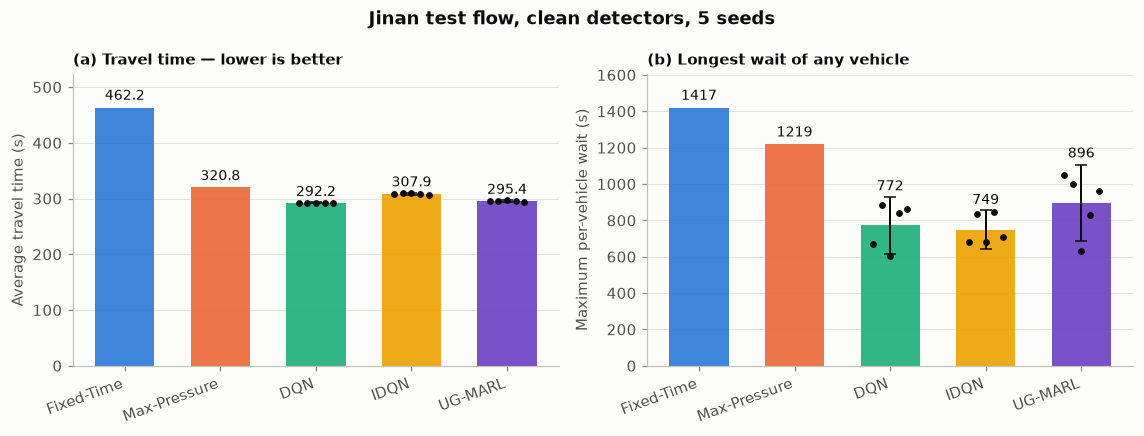

In [11]:
fig = fig_main_comparison(test, AGENTS, ctx.figures)

**Reading.** On clean data the three learned controllers are within 16 s of each other and all
beat Max-Pressure (320.8 s) and Fixed-Time (462.2 s). DQN is best (292.2 s), UG-MARL 3.2 s
behind (295.4 s, CIs separated), IDQN 307.9 s. Seed dots sit almost on top of each other for
travel time; for the maximum wait they do not — one vehicle decides that metric, and the
UG-MARL / DQN / IDQN intervals overlap (896 / 772 / 749 s), all below Max-Pressure's 1219 s.

In [12]:
CONDITION_LABEL = {
    "clean": "clean",
    "noise0.1": "noise 0.1",
    "noise0.2": "noise 0.2",
    "drop0.1": "dropout 10 %",
    "drop0.2": "dropout 20 %",
    "surge1.5": "surge ×1.5",
}


def cond(c: str) -> str:
    return CONDITION_LABEL.get(c, c)


def _ci_points(ax, x, stats: dict, color, seeds=None, marker="o", width=0.0) -> None:
    half_lo, half_hi = stats["mean"] - stats["ci95_low"], stats["ci95_high"] - stats["mean"]
    if not stats["deterministic"]:
        ax.errorbar(x, stats["mean"], yerr=[[half_lo], [half_hi]], color=INK_SECONDARY,
                    capsize=3, linewidth=1.2, zorder=3)
    ax.plot([x], [stats["mean"]], marker=marker, color=color, markersize=7, zorder=4)
    if seeds is not None and not stats["deterministic"]:
        jitter = np.linspace(-0.12, 0.12, len(seeds)) + width
        ax.scatter(x + jitter, seeds, s=10, color=color, alpha=0.45, zorder=2, linewidths=0)


def fig_ablation(study: Study, variants: Sequence[str], conditions: Sequence[str], out=None):
    apply_style()
    metrics = [("avg_travel_time_s", "Average travel time (s)"),
               ("max_waiting_time_s", "Maximum per-vehicle wait (s)")]
    fig, axes = plt.subplots(len(metrics), len(conditions), figsize=(10.5, 6.2), squeeze=False)
    vals = []
    for r, (metric, ylabel) in enumerate(metrics):
        for c, cn in enumerate(conditions):
            ax = axes[r][c]
            for k, m in enumerate(variants):
                s = study.stats(m, cn, metric)
                _ci_points(ax, k, s, CONTROLLER_COLOR[m], study.values(m, cn, metric),
                           marker="D" if m == "ugmarl-nogate" else "o")
                vals.append(f"{short(m)} / {cond(cn)} / {metric.split('_')[0]}: {s['mean']:.1f}")
            ax.set_xticks(range(len(variants)),
                          [short(m).replace("UG-MARL ", "") for m in variants])
            ax.set_xlim(-0.6, len(variants) - 0.4)
            ax.set_ylabel(ylabel if c == 0 else "")
            ax.set_title(f"{cond(cn)}", fontsize=10)
            ax.grid(axis="x", visible=False)
    fig.suptitle("Ablation on the Jinan test flow (mean, 95 % CI, seeds)", fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "ablation", "ablation of gate, attention and ensemble",
        "Full UG-MARL and its three ablations on the Jinan test flow, clean and with detector "
        "noise 0.2. Points: mean over seeds 0–4; bars: 95 % CI; small dots: seeds. −gate uses "
        "the same checkpoints as the full model (diamond); −attention and −ensemble are "
        "trained separately. The y axes do not start at 0.",
        "; ".join(vals) + ". Source: `docs/results/test_ablation.csv`.",
    )

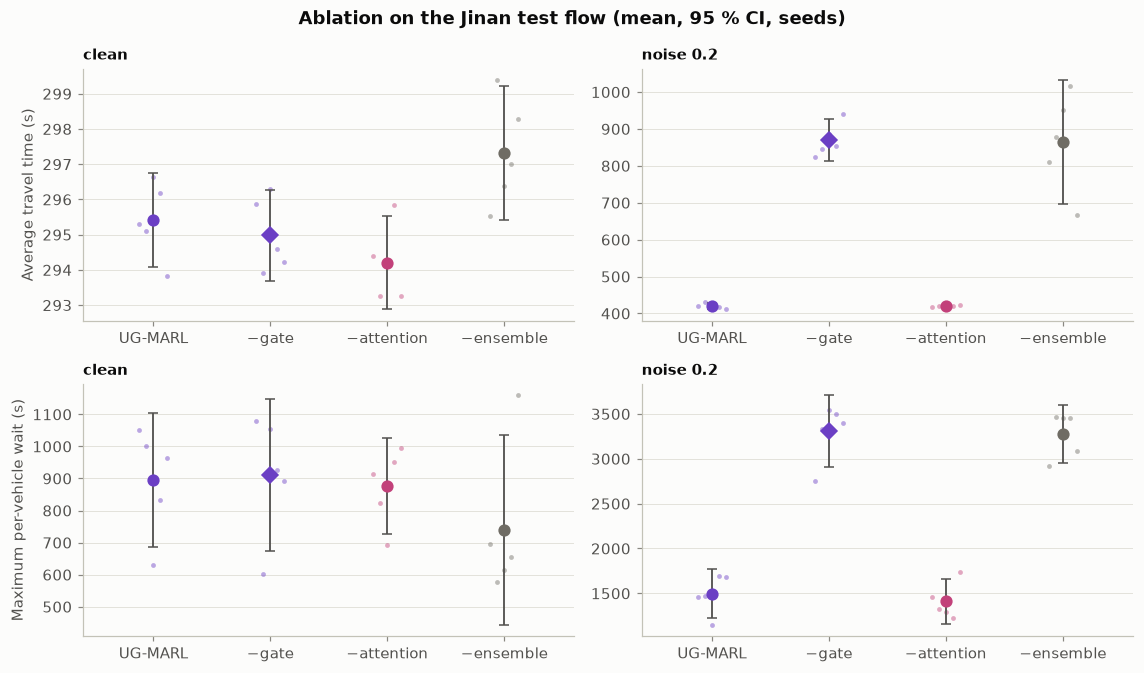

In [13]:
fig = fig_ablation(test, ABLATIONS, CONDS, ctx.figures)

**Reading.** On the clean flow the four variants are within 3 s of each other and the CIs of
full, −gate and −attention overlap: neither the gate nor attention changes clean performance
measurably (H3 not supported). Under noise 0.2 the picture splits in two: the two variants
*with* a gate (full, −attention) stay near 420 s, the two *without* (−gate, −ensemble) go to
865–870 s and a maximum wait above 3200 s. The component that matters for robustness is the
gate (which needs the ensemble); attention is not needed for it.

In [14]:
def fig_wait_tail(
    study: Study, models: Sequence[str], conditions: Sequence[str], out=None
) -> plt.Figure:
    apply_style()
    fig, axes = plt.subplots(1, len(conditions), figsize=(10.5, 4.0), sharey=True)
    vals = []
    for ax, cn in zip(np.atleast_1d(axes), conditions, strict=True):
        for m in models:
            w = np.sort(np.concatenate(
                [study.log(m, cn, "vehicles", s)["wait_s"].to_numpy() for s in study.seeds]
            ))
            share = 1.0 - np.arange(1, len(w) + 1) / len(w)
            ax.step(w, np.maximum(share, 1e-5), where="post", color=CONTROLLER_COLOR[m],
                    linestyle="--" if m == "ugmarl-nogate" else "-",
                    linewidth=2.2 if m == "ugmarl" else 1.5, label=short(m))
            vals.append(f"{short(m)} / {cond(cn)}: p99 {np.percentile(w, 99):.0f} s, "
                        f"max {w.max():.0f} s")
        ax.set_yscale("log")
        ax.set_ylim(1e-4, 1)
        ax.set_xlabel("Waiting time inside the network, x (s)")
        ax.set_title(cond(cn), fontsize=10)
    np.atleast_1d(axes)[0].set_ylabel("Share of vehicles waiting longer than x")
    np.atleast_1d(axes)[0].legend(fontsize=8, loc="upper right")
    fig.suptitle("Tail of the per-vehicle waiting time, Jinan test flow", fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "wait_tail", "tail of the per-vehicle waiting time",
        "Share of vehicles whose total waiting time (seconds at speed < 0.1 m/s inside the "
        "network) exceeds x; the five seeds are pooled (log y axis). Waiting outside the "
        "network — vehicles that cannot enter a full entry road — is not part of this metric.",
        "; ".join(vals) + ". Source: `vehicles_s*.csv` of `results/final/final_test`.",
    )

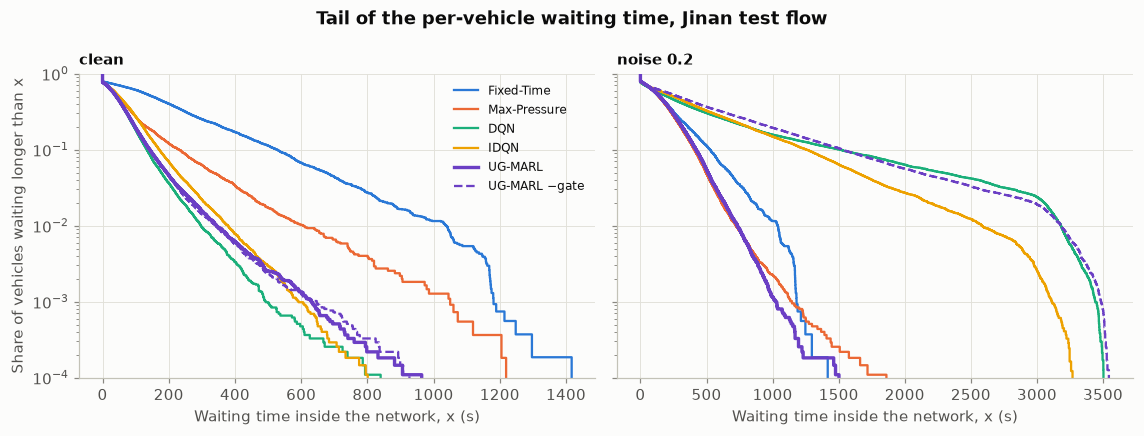

In [15]:
fig = fig_wait_tail(test, [*AGENTS, PAIRED], CONDS, ctx.figures)

**Reading.** Clean: UG-MARL's curve lies between DQN's and Max-Pressure's — close to DQN up to
about the 99th percentile, with a slightly heavier far tail. Noise 0.2: DQN, IDQN and −gate
leave a large share of vehicles waiting more than 1000 s; UG-MARL follows Max-Pressure's
curve. Remember that vehicles blocked outside the network (§0) are missing from the ungated
curves, so their true tails are worse than drawn.

In [16]:
def fig_generalisation(study: Study, models: Sequence[str], out=None) -> plt.Figure:
    apply_style()
    flows = study.conditions
    fig, ax = plt.subplots(figsize=(9.0, 4.0))
    width = 0.8 / len(models)
    vals = []
    for k, m in enumerate(models):
        for j, f in enumerate(flows):
            s = study.stats(m, f, "avg_travel_time_s")
            x = j - 0.4 + (k + 0.5) * width
            ax.bar(x, s["mean"], width=width * 0.9, color=CONTROLLER_COLOR[m],
                   hatch="//" if m == "ugmarl-nogate" else None, edgecolor=SURFACE,
                   label=short(m) if j == 0 else None)
            if not s["deterministic"]:
                err = [[s["mean"] - s["ci95_low"]], [s["ci95_high"] - s["mean"]]]
                ax.errorbar(x, s["mean"], yerr=err, color=INK, capsize=2, linewidth=1)
            vals.append(f"{short(m)} / {f}: {s['mean']:.1f}")
    ax.set_xticks(range(len(flows)), [f"Hangzhou `{f}`".replace("`", "") for f in flows])
    ax.set_ylabel("Average travel time (s)")
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8, ncol=3)
    ax.set_title("Zero-shot on the held-out city (trained on Jinan only)", fontsize=10)
    fig.tight_layout()
    return finish(
        fig, out, "generalisation", "zero-shot generalisation to Hangzhou",
        "Average travel time on the three Hangzhou flow files (4 × 4 network), models trained "
        "and calibrated on Jinan only (τ from Jinan validation). Bars: mean over seeds 0–4; "
        "error bars: 95 % CI. IDQN is not transferable (one network per Jinan intersection).",
        "; ".join(vals) + ". Source: `docs/results/heldout_generalisation.csv`.",
    )

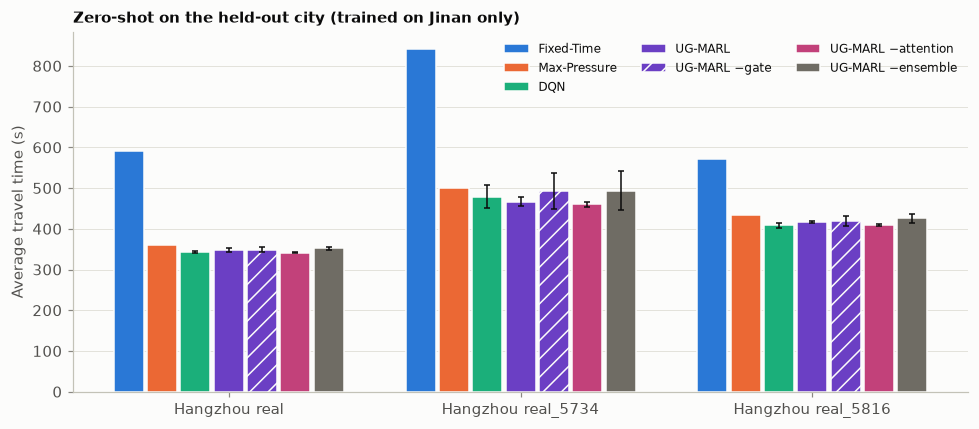

In [17]:
fig = fig_generalisation(held, held.models, ctx.figures)

**Reading.** The order of the agents on Hangzhou is the same as on the Jinan test flow (learned
< Max-Pressure < Fixed-Time). UG-MARL and DQN are level on all three flows (CIs overlap);
the ungated policies (DQN, −gate, −ensemble) have much wider intervals on `real_5734`, the most
congested flow, i.e. some seed-models transfer badly and the gate removes most of that spread
(UG-MARL 466 ± 9 s vs −gate 492 ± 36 s, DQN 479 ± 23 s). −attention is nominally the best variant here as well.

## 3  Robustness and explainability figures (8.2)

In [18]:
def fig_robustness(study: Study, models: Sequence[str], out=None) -> plt.Figure:
    apply_style()
    fig, axes = plt.subplots(1, 3, figsize=(12.0, 4.2), gridspec_kw={"width_ratios": [3, 3, 2]})
    series = [
        (["clean", "noise0.1", "noise0.2"], [0, 0.1, 0.2],
         "Detector noise (std, share of capacity)"),
        (["clean", "drop0.1", "drop0.2"], [0, 10, 20], "Detector dropout (%)"),
    ]
    vals = []
    for ax, (conds, xs, xlabel) in zip(axes[:2], series, strict=True):
        for m in models:
            st = [study.stats(m, c, "avg_travel_time_s") for c in conds]
            mean = [s["mean"] for s in st]
            ax.plot(xs, mean, color=CONTROLLER_COLOR[m], marker="o", markersize=4,
                    linestyle="--" if m == "ugmarl-nogate" else "-",
                    linewidth=2.4 if m == "ugmarl" else 1.5, label=short(m))
            ax.fill_between(xs, [s["ci95_low"] for s in st], [s["ci95_high"] for s in st],
                            color=CONTROLLER_COLOR[m], alpha=0.15, linewidth=0)
            vals.append(f"{short(m)}: " + " → ".join(f"{v:.0f}" for v in mean))
        ax.set_xticks(xs)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Average travel time (s)")
    axes[0].set_title("(a) noise", fontsize=10)
    axes[1].set_title("(b) dropout", fontsize=10)
    axes[0].legend(fontsize=8)
    ax = axes[2]
    for k, m in enumerate(models):
        s = study.stats(m, "surge1.5", "avg_travel_time_s")
        _ci_points(ax, k, s, CONTROLLER_COLOR[m], study.values(m, "surge1.5", "avg_travel_time_s"),
                   marker="D" if m == "ugmarl-nogate" else "o")
        vals.append(f"{short(m)} surge {s['mean']:.0f}")
    ax.set_xticks(range(len(models)), [short(m).replace("UG-MARL ", "") for m in models],
                  rotation=35, ha="right", fontsize=8)
    ax.set_title("(c) demand surge ×1.5", fontsize=10)
    ax.set_ylabel("Average travel time (s)")
    ax.grid(axis="x", visible=False)
    fig.suptitle("Robustness on the Jinan test flow (mean and 95 % CI over 5 seeds)",
                 fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "robustness_degradation", "robustness to detector noise, dropout and surge",
        "Average travel time on the Jinan test flow as detector noise (a) or dropout (b) "
        "grows, and under a demand surge of ×1.5 (c). Lines / points: mean over seeds 0–4; "
        "bands / bars: 95 % CI. −gate (dashed) is the same checkpoints as UG-MARL with the "
        "gate switched off. Noise and dropout change what the controllers observe, not the "
        "traffic; Fixed-Time does not use detectors.",
        "; ".join(vals) + ". Source: `docs/results/test_robustness.csv`.",
    )

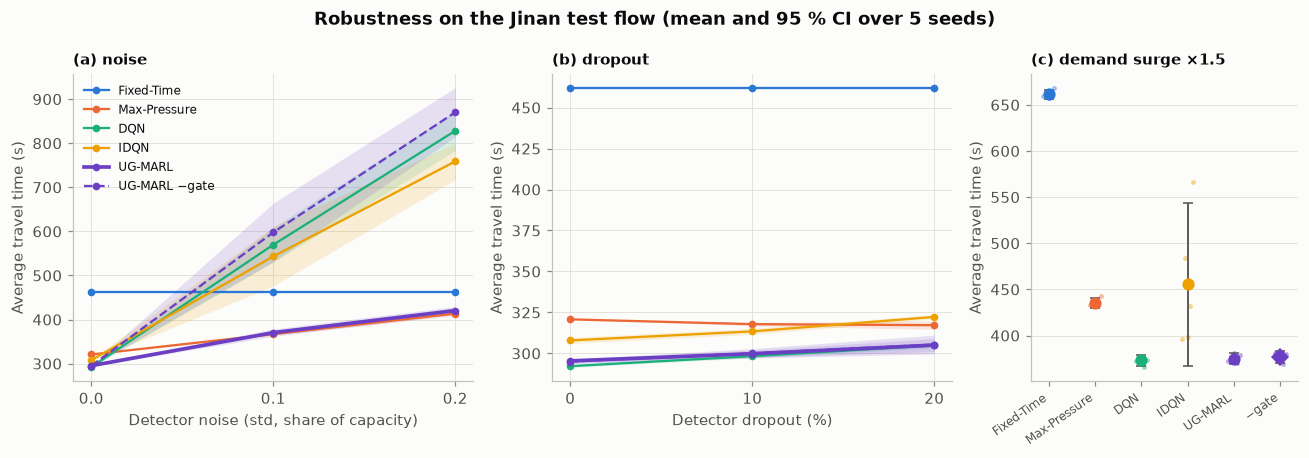

In [19]:
fig = fig_robustness(test, [*AGENTS, PAIRED], ctx.figures)

**Reading.** (a) Detector noise separates the controllers: every learned policy without a gate
more than doubles its travel time at noise 0.2 (759–870 s), while UG-MARL stays on
Max-Pressure's line (370 / 421 s vs 367 / 414 s; CIs overlap, Max-Pressure nominally 3–7 s
lower). UG-MARL does **not** beat Max-Pressure under noise — the gate hands 83–96 % of the
decisions to it, so Max-Pressure on noisy readings is the ceiling. (b) Dropout barely matters
for any controller (< 15 s). (c) Under the surge the learned policies generalise better than
Max-Pressure (373–376 s vs 435 s); IDQN is unstable across seeds.

In [20]:
SEQUENTIAL = LinearSegmentedColormap.from_list("ugmarl_seq", [SURFACE, *BLUE_RAMP])


def fig_regret(study: Study, models: Sequence[str], reference: Sequence[str], out=None):
    apply_style()
    reg, summ = regret_frames(study, models, reference)
    conds = study.conditions
    mat = reg.pivot(index="model", columns="condition", values="regret").loc[models, conds]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw={"width_ratios": [3, 2]})
    im = ax1.imshow(np.log10(1 + mat.to_numpy()), cmap=SEQUENTIAL, aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.iloc[i, j]
            ax1.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                     color=SURFACE if v > 150 else INK)
    ax1.set_xticks(range(len(conds)), [cond(c) for c in conds], rotation=20, ha="right")
    ax1.set_yticks(range(len(models)), [short(m) for m in models])
    ax1.grid(False)
    ax1.set_title("(a) Regret per condition (s)", fontsize=10)
    fig.colorbar(im, ax=ax1, label="log10(1 + regret)", shrink=0.8)
    summ = summ.set_index("model").loc[models]
    y = np.arange(len(models))
    ax2.barh(y - 0.2, summ["max_regret"], height=0.38, color=[CONTROLLER_COLOR[m] for m in models])
    ax2.barh(y + 0.2, summ["mean_regret"], height=0.38, alpha=0.45,
             color=[CONTROLLER_COLOR[m] for m in models])
    for k, m in enumerate(models):
        ax2.text(summ.loc[m, "max_regret"], k - 0.2, f" {summ.loc[m, 'max_regret']:.1f}",
                 va="center", fontsize=8)
        ax2.text(summ.loc[m, "mean_regret"], k + 0.2, f" {summ.loc[m, 'mean_regret']:.1f}",
                 va="center", fontsize=8, color=INK_SECONDARY)
    ax2.set_yticks(y, [short(m) for m in models])
    ax2.invert_yaxis()
    ax2.set_xscale("symlog", linthresh=10)
    ax2.set_xlabel("Regret (s): largest (solid) and mean (light) over the conditions")
    ax2.set_title("(b) Worst-case and mean regret", fontsize=10)
    ax2.grid(axis="y", visible=False)
    fig.suptitle("Regret against the best of the five agents in each condition",
                 fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "regret", "regret against the best agent per condition",
        "Regret = a model's mean travel time − the lowest mean among the five agents "
        f"({', '.join(short(m) for m in reference)}) in the same condition, Jinan test flow, "
        "seeds 0–4. (a) per condition (colour on a log scale); (b) each model's largest and "
        "mean regret over the six conditions (symmetric-log x axis). Descriptive statistic "
        "fixed before the test runs.",
        "; ".join(f"{short(m)}: max {summ.loc[m, 'max_regret']:.1f} s "
                  f"({cond(summ.loc[m, 'worst_condition'])}), "
                  f"mean {summ.loc[m, 'mean_regret']:.1f} s" for m in models) + ".",
    )

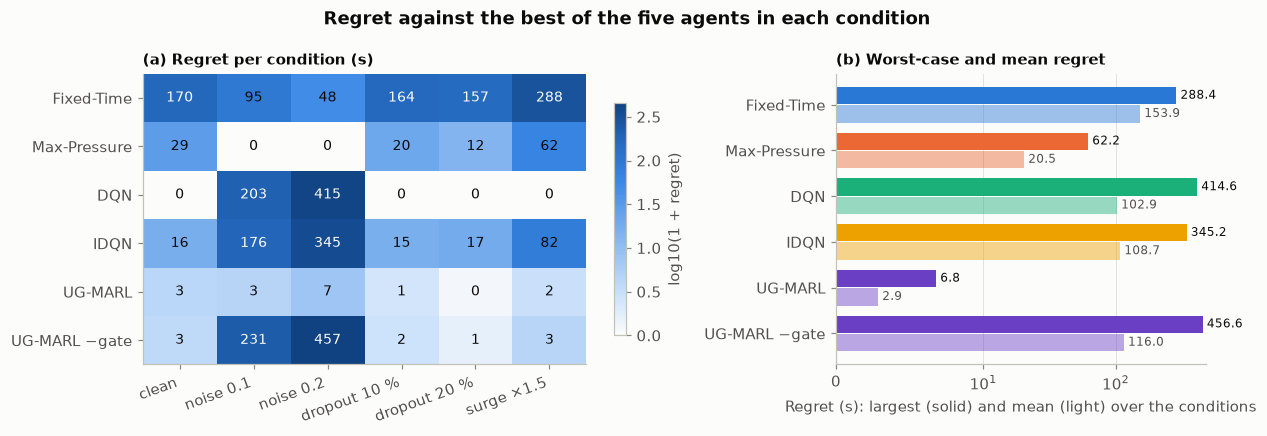

In [21]:
fig = fig_regret(test, [*AGENTS, PAIRED], AGENTS, ctx.figures)

**Reading.** No single baseline is good everywhere: DQN is best in four conditions and worst by
far under noise (415 s regret); Max-Pressure is best under noise and 20–62 s behind elsewhere.
UG-MARL is never the best agent in a condition and never far from it: largest regret 6.8 s
(noise 0.2), mean 2.9 s. That is the claim the report can make — "close to the better
controller in every tested condition" — not "best".

In [22]:
_IID = re.compile(r"_(\d+)_(\d+)$")


def grid_xy(iid: str) -> tuple[int, int]:
    m = _IID.search(iid)
    if not m:
        raise ValueError(f"cannot place {iid!r} on the grid")
    return int(m.group(1)), int(m.group(2))


def grid_panel(
    ax: plt.Axes,
    values: Mapping[str, float],
    cmap,
    vmin: float,
    vmax: float,
    fmt: str = "{:.0f}",
    marks: Mapping[str, bool] | None = None,
):
    """Draw one value per intersection at its place in the network (x → east, y → north).
    ``marks`` adds a ``*`` to cells whose difference is clear (CI excludes 0)."""
    xs, ys = zip(*(grid_xy(i) for i in values), strict=True)
    nx, ny = max(xs), max(ys)
    grid = np.full((ny, nx), np.nan)
    for iid, v in values.items():
        x, y = grid_xy(iid)
        grid[y - 1, x - 1] = v
    im = ax.imshow(grid, cmap=cmap, vmin=vmin, vmax=vmax, origin="lower", aspect="equal")
    for iid, v in values.items():
        x, y = grid_xy(iid)
        star = "*" if marks and marks.get(iid) else ""
        dark = cmap is SEQUENTIAL and (v - vmin) / max(vmax - vmin, 1e-12) > 0.6
        ax.text(x - 1, y - 1, fmt.format(v) + star, ha="center", va="center", fontsize=8,
                color=SURFACE if dark else INK)
    ax.set_xticks(range(nx), [str(i + 1) for i in range(nx)])
    ax.set_yticks(range(ny), [str(i + 1) for i in range(ny)])
    ax.set_xlabel("column (west → east)")
    ax.set_ylabel("row (south → north)")
    ax.grid(False)
    return im


def fig_gate_firing(
    study: Study, model: str, conditions: Sequence[str], grid_conditions: Sequence[str],
    window_s: int = 300, out=None,
) -> plt.Figure:
    apply_style()
    fig = plt.figure(figsize=(12.0, 7.4))
    gs = fig.add_gridspec(2, 2 * len(grid_conditions), height_ratios=[1, 1])
    ax1 = fig.add_subplot(gs[0, : len(grid_conditions)])
    ax2 = fig.add_subplot(gs[0, len(grid_conditions) :])
    ramp = plt.get_cmap("viridis")(np.linspace(0.05, 0.9, len(conditions)))
    dec = {c: pd.concat([study.log(model, c, "decisions", s) for s in study.seeds])
           for c in conditions}
    data = [np.log10(d["sigma"] / d["tau"]).to_numpy() for d in dec.values()]
    bp = ax1.boxplot(data, showfliers=False, patch_artist=True, widths=0.55)
    for patch, col in zip(bp["boxes"], ramp, strict=True):
        patch.set(facecolor=col, edgecolor=INK_SECONDARY, alpha=0.75)
    for med in bp["medians"]:
        med.set(color=INK, linewidth=1.8)
    ax1.axhline(0, color=INK, linestyle=":", linewidth=1.2)
    ax1.text(0.99, 0.02, "the gate fires above the dotted line (σ > τ)", fontsize=8,
             color=INK_SECONDARY, transform=ax1.transAxes, ha="right")
    ax1.set_xticks(range(1, len(conditions) + 1), [cond(c) for c in conditions], rotation=15)
    ax1.set_ylabel("log10(σ / τ)")
    ax1.set_title("(a) Uncertainty relative to the threshold", fontsize=10)
    ax1.grid(axis="x", visible=False)
    vals = []
    for c, col in zip(conditions, ramp, strict=True):
        d = dec[c]
        r = d.groupby(d["t"] // window_s)["fallback"].mean()
        ax2.plot((r.index + 0.5) * window_s / 60, r.to_numpy(), color=col, marker="o",
                 markersize=3, label=cond(c))
        vals.append(f"{cond(c)}: fallback {d['fallback'].mean():.3f}")
    ax2.set_xlabel("Time in the episode (min)")
    ax2.set_ylabel("Share of decisions handed to Max-Pressure")
    ax2.set_ylim(0, 1.02)
    ax2.legend(fontsize=8, ncol=2)
    ax2.set_title(f"(b) Fallback rate per {window_s // 60}-minute window", fontsize=10)
    for k, c in enumerate(grid_conditions):
        ax = fig.add_subplot(gs[1, 2 * k : 2 * k + 2])
        rate = dec[c].groupby("iid")["fallback"].mean().to_dict()
        im = grid_panel(ax, rate, SEQUENTIAL, 0, 1, "{:.2f}")
        ax.set_title(f"(c{k + 1}) Fallback rate per intersection — {cond(c)}", fontsize=10)
        fig.colorbar(im, ax=ax, shrink=0.75, label="fallback rate")
    fig.suptitle(f"When the gate fires — {short(model)}, Jinan test flow, 5 seeds pooled",
                 fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "gate_firing", "when and where the uncertainty gate fires",
        "(a) Ensemble disagreement σ of every decision divided by that model's threshold τ "
        "(boxes: quartiles; whiskers 1.5 IQR; outliers hidden). (b) Share of decisions handed "
        f"to Max-Pressure per {window_s // 60}-minute window. (c) The same share per "
        "intersection, drawn at the intersection's place in the 3 × 4 network. Seeds 0–4 "
        "pooled; τ per seed-model from Jinan validation (p* = 80).",
        "; ".join(vals)
        + ". Source: `decisions_s*.csv` (= `docs/results/test_safety_explain.csv`).",
    )

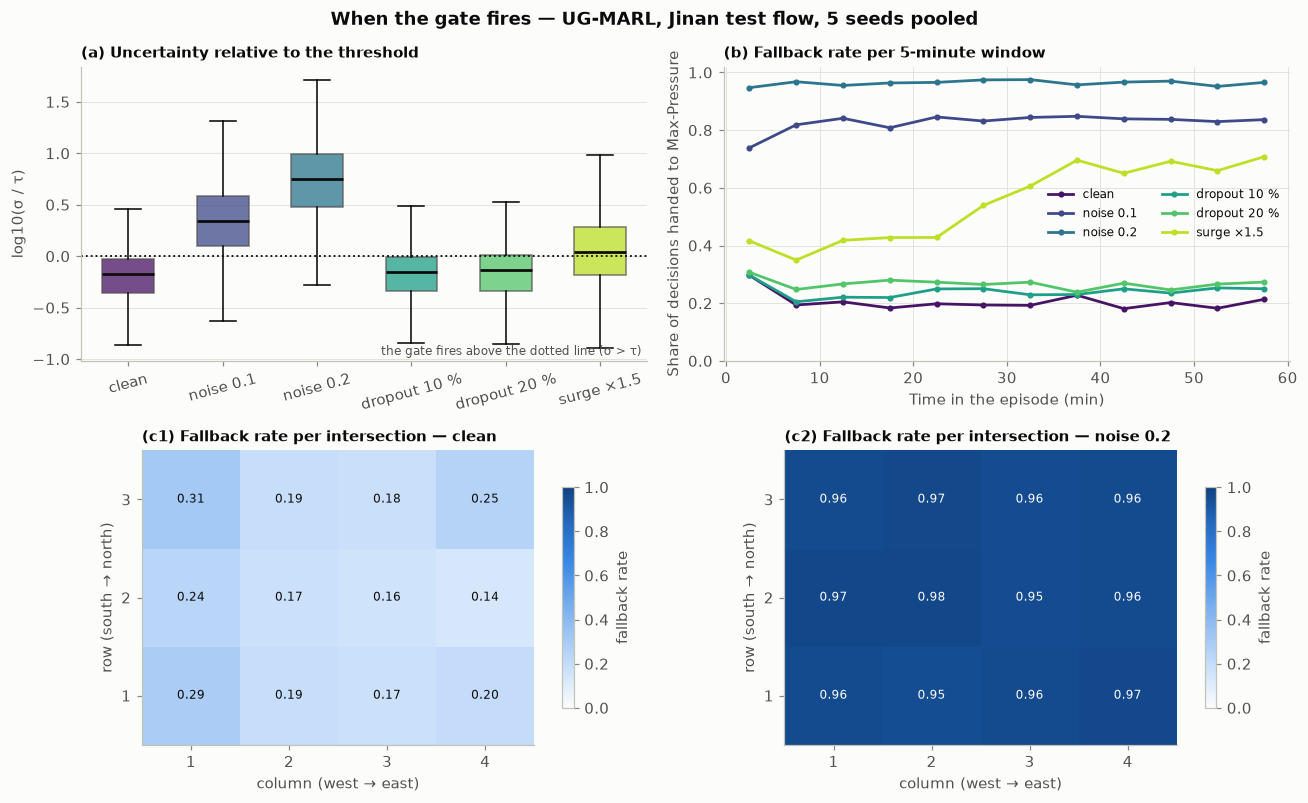

In [23]:
fig = fig_gate_firing(test, PROPOSED, test.conditions, CONDS, cfg["case_window_s"], ctx.figures)

**Reading.** (a) σ reacts strongly to detector noise (median σ ≈ 2× τ at noise 0.1, ≈ 6× at
0.2), hardly at all to dropout, and moderately to the surge. (b) On clean data the gate fires
on about 20 % of decisions all hour (by construction: τ is the 80th percentile of clean
validation σ); under the surge the rate climbs from 38 % to 68 % as queues build — the gate
reads heavy traffic it was not trained on as uncertainty. (c) On clean data it fires more
in the west column (0.24–0.31) than in the two centre columns (0.16–0.19); under noise it
fires everywhere. σ flags *unfamiliar inputs*; whether it flags *wrong actions* is a separate
question (Phase 6: Spearman ρ(σ, |TD|) ≈ 0.03).

In [24]:
def attention_frame(study: Study, model: str, condition: str) -> pd.DataFrame:
    """Mean attention weight per intersection and slot; an absent neighbour stays NaN."""
    d = pd.concat([study.log(model, condition, "decisions", s) for s in study.seeds])
    cols = ["attn_self", "attn_E", "attn_N", "attn_W", "attn_S"]
    return d.groupby("iid")[cols].mean().replace(0.0, np.nan)


def fig_attention_map(study: Study, model: str, condition: str = "clean", out=None):
    apply_style()
    att = attention_frame(study, model, condition)
    fig, ax = plt.subplots(figsize=(8.6, 6.0))
    offsets = {"E": (1, 0), "N": (0, 1), "W": (-1, 0), "S": (0, -1)}
    top = float(np.nanmax(att[["attn_E", "attn_N", "attn_W", "attn_S"]].to_numpy()))
    for iid, row in att.iterrows():
        x, y = grid_xy(iid)
        ax.scatter([x], [y], s=2600 * row["attn_self"], color=VIOLET, alpha=0.25, zorder=2)
        ax.text(x, y, f"{row['attn_self']:.2f}", ha="center", va="center", fontsize=9, zorder=4)
        for slot, (dx, dy) in offsets.items():
            w = row[f"attn_{slot}"]
            if np.isnan(w):
                continue
            ax.annotate("", xy=(x + 0.14 * dx, y + 0.14 * dy),
                        xytext=(x + 0.46 * dx, y + 0.46 * dy),
                        arrowprops={"arrowstyle": "-|>", "color": SEQUENTIAL(0.25 + 0.75 * w / top),
                                    "linewidth": 1 + 5 * w / top}, zorder=3)
            ax.text(x + 0.33 * dx + 0.09 * abs(dy), y + 0.33 * dy + 0.09 * abs(dx), f"{w:.2f}",
                    fontsize=7, color=INK_SECONDARY, ha="center", va="center")
    xs, ys = zip(*(grid_xy(i) for i in att.index), strict=True)
    ax.set_xlim(0.4, max(xs) + 0.6)
    ax.set_ylim(0.4, max(ys) + 0.6)
    ax.set_xticks(range(1, max(xs) + 1))
    ax.set_yticks(range(1, max(ys) + 1))
    ax.set_xlabel("column (west → east)")
    ax.set_ylabel("row (south → north)")
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_title(f"Mean attention weights — {short(model)}, {cond(condition)} test flow",
                 fontsize=10)
    fig.tight_layout()
    mean = att.mean()
    return finish(
        fig, out, "attention_map", "attention weights on the network",
        "Mean attention weight of every intersection on itself (number in the circle; circle "
        "area ∝ weight) and on each existing neighbour (arrow from the neighbour, width and "
        "shade ∝ weight), over all decisions of the five seed-models on the clean Jinan test "
        "flow. The weights show where the encoder looks; they are not a measure of a "
        "neighbour's influence on the chosen phase (see the faithfulness check).",
        "Mean over intersections: " + ", ".join(
            f"{c.split('_')[1]} {mean[c]:.3f}" for c in att.columns) + ".",
    )

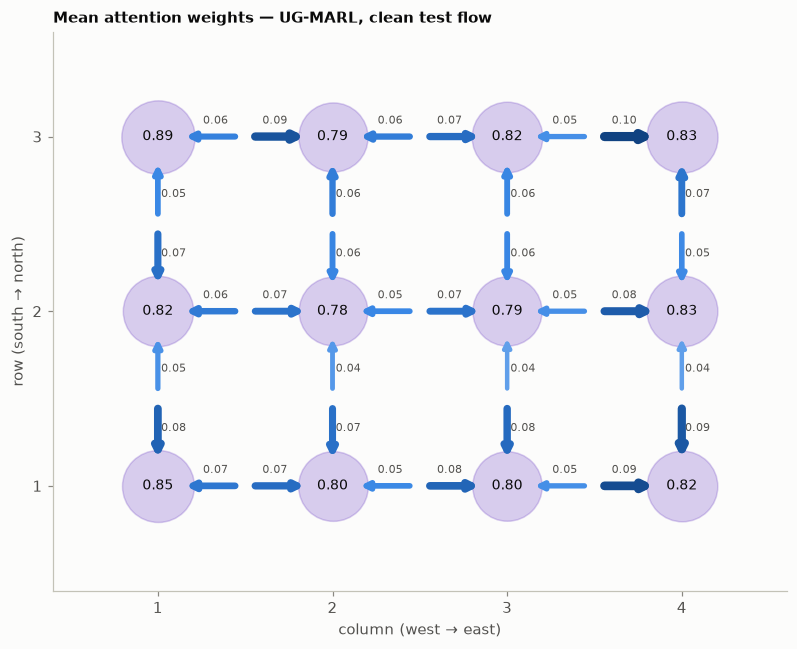

In [25]:
fig = fig_attention_map(test, PROPOSED, "clean", ctx.figures)

**Reading.** Every intersection puts 78–89 % of its attention on itself and 4–10 % on each
neighbour; edge intersections (fewer neighbours) put more on themselves. There is a mild
pattern — the western neighbour gets a little more (0.07–0.10) than the eastern one
(0.05–0.07) — but the map is close to uniform. Together with H3 (no travel-time gain from
attention) this says the learned policy is mostly local. Whether the small weights at least
*rank* the neighbours correctly is tested in §8.

## 4  Error analysis: where does UG-MARL win and lose? (8.4)

UG-MARL is compared with **both DQN and Max-Pressure, in both conditions** (clean and noise
0.2); −gate (the same checkpoints with the gate off) is the paired row. Travel time exists per
vehicle only, so the per-intersection quantity is **waiting-vehicle-seconds** (waiting vehicles
on the incoming lanes × seconds, from the traces); travel time is broken down by the trip's
start window and by route group.

In [26]:
def seed_stats(df: pd.DataFrame, keys: Sequence[str], value: str) -> pd.DataFrame:
    """mean, std, 95 % CI and n of ``value`` over seeds, per ``keys``."""
    rows = []
    for k, g in df.groupby(list(keys), sort=False):
        k = k if isinstance(k, tuple) else (k,)
        s = summarise(g[value].tolist())
        rows.append({**dict(zip(keys, k, strict=True)), **s})
    return pd.DataFrame(rows)


def seed_difference(
    a: pd.DataFrame, b: pd.DataFrame, keys: Sequence[str], value: str
) -> pd.DataFrame:
    """Seed-by-seed difference ``a − b`` with mean, std and 95 % CI."""
    on = [*keys, "seed"]
    m = a[[*on, value]].merge(b[[*on, value]], on=on, suffixes=("_a", "_b"))
    m["diff"] = m[f"{value}_a"] - m[f"{value}_b"]
    out = seed_stats(m, keys, "diff")
    means = m.groupby(list(keys), sort=False)[[f"{value}_a", f"{value}_b"]].mean().reset_index()
    out = out.merge(means, on=list(keys))
    out["clear"] = (out["ci95_low"] > 0) | (out["ci95_high"] < 0)
    return out


def comparison(
    frames: Mapping[str, pd.DataFrame],
    table: str,
    keys: Sequence[str],
    value: str,
    model: str,
    baseline: str,
    condition: str,
) -> pd.DataFrame:
    """``model − baseline`` for one breakdown table and condition (see :func:`seed_difference`)."""
    f = frames[table]
    f = f[f["condition"] == condition]
    d = seed_difference(f[f["model"] == model], f[f["model"] == baseline], keys, value)
    d.insert(0, "condition", condition)
    d.insert(0, "baseline", baseline)
    d.insert(0, "model", model)
    return d


def comparisons(
    frames: Mapping[str, pd.DataFrame],
    table: str,
    keys: Sequence[str],
    value: str,
    model: str,
    baselines: Sequence[str],
    conditions: Sequence[str],
) -> dict[tuple[str, str], pd.DataFrame]:
    """``{(baseline, condition): model − baseline}`` for one breakdown table."""
    return {
        (b, c): comparison(frames, table, keys, value, model, b, c)
        for c in conditions
        for b in baselines
    }


def comparison_overview(comps: Mapping[tuple[str, str], pd.DataFrame], key: str) -> pd.DataFrame:
    """One row per (baseline, condition): how many groups differ clearly and in which
    direction, and the smallest / largest mean difference."""
    rows = []
    for (b, c), d in comps.items():
        rows.append(
            {
                "baseline": b,
                "condition": c,
                "groups": len(d),
                "clearly_lower": int((d["clear"] & (d["mean"] < 0)).sum()),
                "clearly_higher": int((d["clear"] & (d["mean"] > 0)).sum()),
                "level": int((~d["clear"]).sum()),
                "min_diff": float(d["mean"].min()),
                "at_min": d.loc[d["mean"].idxmin(), key],
                "max_diff": float(d["mean"].max()),
                "at_max": d.loc[d["mean"].idxmax(), key],
            }
        )
    return pd.DataFrame(rows)


DIVERGING = LinearSegmentedColormap.from_list("ugmarl_div", [BLUE, SURFACE, ORANGE])


def fig_error_intersections(
    comps: Mapping[tuple[str, str], pd.DataFrame], model: str, out=None, name="error_intersections"
) -> plt.Figure:
    """``comps[(baseline, condition)]`` = :func:`analysis.comparison` on ``intersections``."""
    apply_style()
    baselines = list(dict.fromkeys(b for b, _ in comps))
    conds = list(dict.fromkeys(c for _, c in comps))
    size = (5.6 * len(baselines), 3.9 * len(conds))
    fig, axes = plt.subplots(len(conds), len(baselines), figsize=size, squeeze=False)
    vals = []
    for r, c in enumerate(conds):
        for k, b in enumerate(baselines):
            d = comps[(b, c)].set_index("iid")
            rel = 100 * d["mean"] / d["wait_veh_s_b"]
            lim = max(5.0, float(np.abs(rel).max()))
            im = grid_panel(axes[r][k], rel.to_dict(), DIVERGING, -lim, lim, "{:+.0f}",
                            d["clear"].to_dict())
            axes[r][k].set_title(f"{short(model)} − {short(b)}, {cond(c)}", fontsize=10)
            fig.colorbar(im, ax=axes[r][k], shrink=0.75, label="difference (%)")
            tot = 100 * d["mean"].sum() / d["wait_veh_s_b"].sum()
            vals.append(f"vs {short(b)} / {cond(c)}: network {tot:+.1f} %, "
                        f"{int(d['clear'].sum())} of {len(d)} intersections clear")
    fig.suptitle("Where the waiting happens: waiting-vehicle-seconds per intersection, "
                 "difference to each baseline", fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, name, "difference in waiting per intersection",
        f"Waiting-vehicle-seconds (Σ over the episode of waiting vehicles on the incoming "
        f"lanes × seconds) of {short(model)} minus the baseline's, in percent of the "
        "baseline, per intersection at its place in the network; blue = fewer waiting "
        "vehicles than the baseline, orange = more. Mean over seeds 0–4; * = the 95 % CI of "
        "the difference excludes 0. Jinan test flow, read from the saved traces.",
        "; ".join(vals) + ".",
    )

,baseline,condition,groups,clearly_lower,clearly_higher,level,min_diff,at_min,max_diff,at_max
0,dqn,clean,12,0,4,8,21,intersection_3_3,3612,intersection_2_2
1,max_pressure,clean,12,12,0,0,-23230,intersection_1_3,-5319,intersection_3_1
2,ugmarl-nogate,clean,12,1,1,10,-1434,intersection_2_3,3085,intersection_1_3
3,dqn,noise0.2,12,12,0,0,-249861,intersection_1_1,-27337,intersection_4_3
4,max_pressure,noise0.2,12,0,1,11,-3953,intersection_4_1,14664,intersection_2_2
5,ugmarl-nogate,noise0.2,12,12,0,0,-247427,intersection_1_2,-42848,intersection_4_3


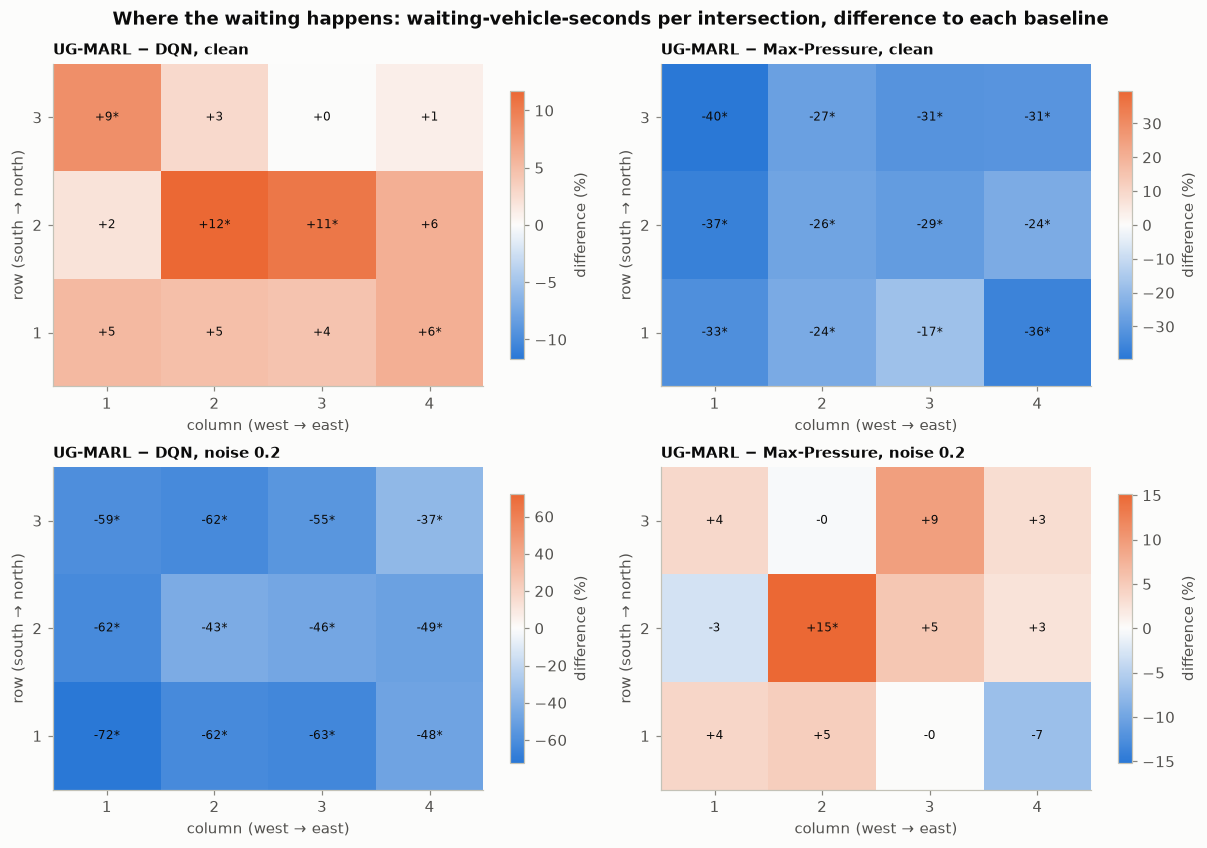

In [27]:
REF = [*BASELINES, PAIRED]
ci = comparisons(frames_all, "intersections", ["iid"], "wait_veh_s", PROPOSED, REF, CONDS)
cw = comparisons(frames_all, "windows", ["window"], "travel_s", PROPOSED, REF, CONDS)
cl = comparisons(frames_all, "length", ["length_group"], "travel_s", PROPOSED, REF, CONDS)
ct = comparisons(frames_all, "turn", ["turn_group"], "travel_s", PROPOSED, REF, CONDS)
display(show(comparison_overview(ci, "iid").round(0), "Waiting-vehicle-seconds per intersection, UG-MARL − baseline: number of intersections that differ clearly"))
fig = fig_error_intersections({k: v for k, v in ci.items() if k[0] in BASELINES}, PROPOSED, ctx.figures)

**Reading.** *vs DQN, clean:* UG-MARL has more waiting at **every** intersection (+0 to +12 %),
clearly so at 4 of 12; the largest gaps are in the middle row and column (2_2, 3_2) and at
1_3. There is no single place where it loses — the 3.2 s is a small deficit spread over the
network. *vs Max-Pressure, clean:* 17–40 % less waiting at all 12 intersections, all clear.
*vs DQN, noise 0.2:* 37–72 % less at all 12. *vs Max-Pressure, noise 0.2:* level at 11 of 12
(one clear, 2_2: +15 %). The paired −gate row (table) shows the gate is not where the clean
deficit comes from: 10 of 12 intersections are level between gate on and off.

In [28]:
def fig_error_windows(
    comps: Mapping[tuple[str, str], pd.DataFrame], model: str, window_s: int, out=None
) -> plt.Figure:
    """``comps[(baseline, condition)]`` = :func:`analysis.comparison` on ``windows``."""
    apply_style()
    conds = list(dict.fromkeys(c for _, c in comps))
    fig, axes = plt.subplots(1, len(conds), figsize=(5.4 * len(conds), 4.0), squeeze=False)
    vals = []
    for ax, c in zip(axes[0], conds, strict=True):
        for b, cc in comps:
            if cc != c:
                continue
            d = comps[(b, c)].sort_values("window")
            x = (d["window"] + 0.5) * window_s / 60
            style = "--" if b == "ugmarl-nogate" else "-"
            ax.plot(x, d["mean"], color=CONTROLLER_COLOR[b], marker="o", linestyle=style,
                    label=f"− {short(b)}")
            ax.fill_between(x, d["ci95_low"], d["ci95_high"], color=CONTROLLER_COLOR[b],
                            alpha=0.15, linewidth=0)
            vals.append(f"vs {short(b)} / {cond(c)}: " + ", ".join(f"{v:+.1f}" for v in d["mean"]))
        ax.axhline(0, color=INK, linewidth=1)
        ax.set_yscale("symlog", linthresh=10)
        ax.set_xlabel("Scheduled start of the trip (min)")
        ax.set_ylabel(f"Travel time, {short(model)} − baseline (s)")
        ax.set_title(cond(c), fontsize=10)
        ax.legend(fontsize=8)
    fig.suptitle("When the difference arises: travel time by start window", fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "error_windows", "difference in travel time by start window",
        f"Mean travel time of the trips scheduled to start in each {window_s // 60}-minute "
        f"window, {short(model)} minus each baseline (below 0 = {short(model)} faster). Mean "
        "over seeds 0–4 with 95 % CI band; symmetric-log y axis (linear within ±10 s). Travel "
        "time counts from the scheduled start, so time blocked outside the network and trips "
        "unfinished at 3600 s are included, as in the simulator's average.",
        "; ".join(vals) + ".",
    )

,baseline,condition,groups,clearly_lower,clearly_higher,level,min_diff,at_min,max_diff,at_max
0,dqn,clean,6,0,5,1,0.2,5,4.5,3
1,max_pressure,clean,6,6,0,0,-32,1,-4.6,5
2,ugmarl-nogate,clean,6,0,0,6,-3,1,2.7,2
3,dqn,noise0.2,6,6,0,0,-731.7,1,-11.3,5
4,max_pressure,noise0.2,6,0,1,5,-0.2,5,17.2,3
5,ugmarl-nogate,noise0.2,6,6,0,0,-772.3,1,-14.1,5


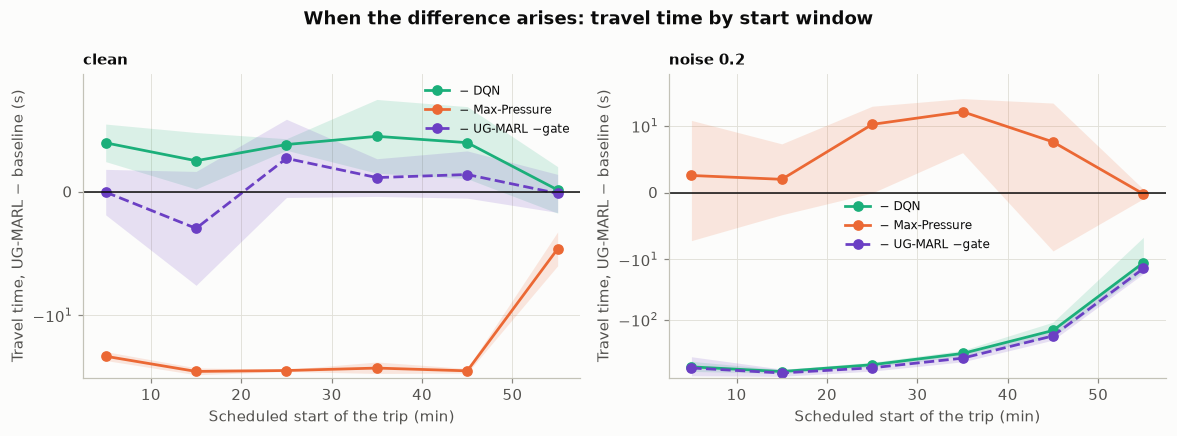

In [29]:
display(show(comparison_overview(cw, "window").round(1), "Travel time per 10-minute start window, UG-MARL − baseline (s)"))
fig = fig_error_windows(cw, PROPOSED, cfg["window_s"], ctx.figures)

**Reading.** Clean: the deficit to DQN is 2.5–4.5 s in each of the first five windows (clear in
all five) and vanishes in the last, where most trips are unfinished for every controller. It
is constant over the hour, not tied to a demand peak. Gate vs −gate: level in all six windows.
Noise 0.2: against DQN and −gate the gain is 150–770 s per trip in the first 50 minutes;
against Max-Pressure UG-MARL is level in five windows and 17 s slower in one (30–40 min).

In [30]:
def stack_comparisons(comps: Mapping[tuple[str, str], pd.DataFrame]) -> pd.DataFrame:
    return pd.concat(list(comps.values()), ignore_index=True)


def fig_error_routes(
    comps: Mapping[tuple[str, str], pd.DataFrame], model: str, by: str, out=None
) -> plt.Figure:
    """``comps[(baseline, condition)]`` = :func:`analysis.comparison` on a route table."""
    apply_style()
    conds = list(dict.fromkeys(c for _, c in comps))
    fig, axes = plt.subplots(1, len(conds), figsize=(5.4 * len(conds), 4.0), squeeze=False)
    vals = []
    for ax, c in zip(axes[0], conds, strict=True):
        bs = [b for b, cc in comps if cc == c]
        for k, b in enumerate(bs):
            d = comps[(b, c)].sort_values(by)
            x = np.arange(len(d)) + (k - (len(bs) - 1) / 2) * 0.22
            ax.errorbar(x, d["mean"], yerr=[d["mean"] - d["ci95_low"], d["ci95_high"] - d["mean"]],
                        fmt="D" if b == "ugmarl-nogate" else "o", color=CONTROLLER_COLOR[b],
                        capsize=3, label=f"− {short(b)}")
            ax.set_xticks(range(len(d)), d[by])
            vals.append(f"vs {short(b)} / {cond(c)}: " + ", ".join(
                f"{g} {v:+.1f}" for g, v in zip(d[by], d["mean"], strict=True)))
        ax.axhline(0, color=INK, linewidth=1)
        ax.set_yscale("symlog", linthresh=10)
        ax.set_xlabel("Intersections on the route" if by == "length_group" else "Route type")
        ax.set_ylabel(f"Travel time, {short(model)} − baseline (s)")
        ax.set_title(cond(c), fontsize=10)
        ax.grid(axis="x", visible=False)
        ax.legend(fontsize=8)
    fig.suptitle("Which trips differ: travel time by route group", fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "error_routes", "difference in travel time by route group",
        f"Mean travel time per route group, {short(model)} minus each baseline (below 0 = "
        f"{short(model)} faster); mean over seeds 0–4, 95 % CI; symmetric-log y axis. Routes "
        "come from the test flow file, joined to the saved per-vehicle logs by flow index "
        "(read-only, Decision Log 13 Nov).",
        "; ".join(vals) + ".",
    )

,baseline,condition,length_group,travel_s_a,travel_s_b,mean,ci95_low,ci95_high,clear
0,dqn,clean,1,121.4,119.7,1.6,0,3.2,yes
1,dqn,clean,2,191.4,190.1,1.3,0.6,2,yes
2,dqn,clean,3,305,303.5,1.5,-6.9,9.9,no
3,dqn,clean,4+,403.6,398,5.6,3.6,7.6,yes
4,max_pressure,clean,1,121.4,133.3,-12,-13.6,-10.3,yes
5,max_pressure,clean,2,191.4,207.8,-16.5,-17.3,-15.6,yes
6,max_pressure,clean,3,305,326.4,-21.4,-27.3,-15.6,yes
7,max_pressure,clean,4+,403.6,440.3,-36.7,-38.3,-35.2,yes
8,ugmarl-nogate,clean,1,121.4,120.9,0.4,0.1,0.8,yes
9,ugmarl-nogate,clean,2,191.4,191.8,-0.4,-2.2,1.4,no


,baseline,condition,turn_group,travel_s_a,travel_s_b,mean,ci95_low,ci95_high,clear
0,dqn,clean,straight,310.5,311.1,-0.5,-11.2,10.1,no
1,dqn,clean,turning,292.7,288.8,3.9,2.3,5.4,yes
2,max_pressure,clean,straight,310.5,312.4,-1.9,-9.3,5.5,no
3,max_pressure,clean,turning,292.7,322.3,-29.6,-30.6,-28.5,yes
4,ugmarl-nogate,clean,straight,310.5,310.3,0.2,-1.1,1.6,no
5,ugmarl-nogate,clean,turning,292.7,292.2,0.5,-0.8,1.7,no
6,dqn,noise0.2,straight,516.1,1039.6,-523.5,-601.2,-445.8,yes
7,dqn,noise0.2,turning,403.3,790.3,-387,-427.4,-346.5,yes
8,max_pressure,noise0.2,straight,516.1,496.2,19.9,14.1,25.7,yes
9,max_pressure,noise0.2,turning,403.3,398.9,4.5,-0.2,9.2,no


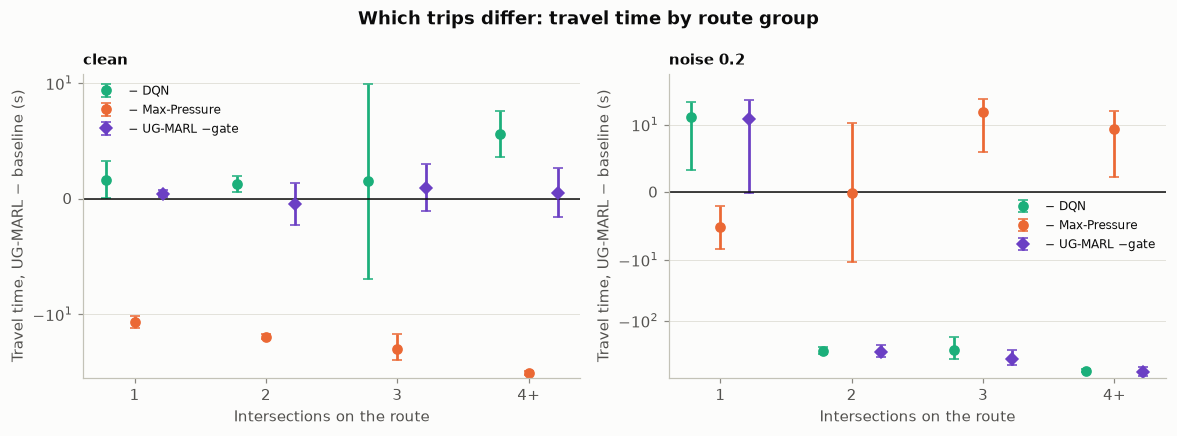

In [31]:
display(show(stack_comparisons(cl)[["baseline", "condition", "length_group", "travel_s_a", "travel_s_b", "mean", "ci95_low", "ci95_high", "clear"]]
        .round(1), "Travel time by number of intersections on the route: UG-MARL (a), baseline (b), difference a − b (s)"))
display(show(stack_comparisons(ct)[["baseline", "condition", "turn_group", "travel_s_a", "travel_s_b", "mean", "ci95_low", "ci95_high", "clear"]]
        .round(1), "Travel time by route type (straight through vs with at least one turn)"))
fig = fig_error_routes(cl, PROPOSED, "length_group", ctx.figures)

**Reading.** Clean, vs DQN: +1.3 to +1.6 s for trips through one to three intersections and
+5.6 s for trips through four or more — the deficit grows with route length, as expected if a
little is lost at each intersection. It is carried by turning trips (+3.9 s, clear); straight
trips are level. Vs Max-Pressure the gain also grows with route length (−12 → −37 s). Noise
0.2, vs Max-Pressure: UG-MARL is 5 s faster on one-intersection trips and 9–16 s slower on
long ones, and the loss is on straight trips (+20 s): the mixed policy (4 % learned decisions
on noisy inputs) is slightly worse than pure Max-Pressure at keeping through traffic moving.

### 4.1  What follows a gate intervention

In [32]:
def after_decision_queue(
    decisions: pd.DataFrame, trace: pd.DataFrame, horizon_s: int = 60
) -> pd.DataFrame:
    """For every logged decision: waiting vehicles at that intersection at the decision and
    their mean over the following ``horizon_s`` seconds (from the trace)."""
    q = _lane_columns(trace)
    tr = trace[["t", "iid"]].copy()
    tr["waiting"] = trace[q].sum(axis=1)
    out = []
    for iid, d in decisions.groupby("iid", sort=True):
        g = tr[tr["iid"] == iid].sort_values("t")
        times, waiting = g["t"].to_numpy(), g["waiting"].to_numpy(float)
        csum = np.concatenate([[0.0], np.cumsum(waiting)])
        t0 = d["t"].to_numpy()
        lo = np.searchsorted(times, t0, side="left")
        hi = np.searchsorted(times, t0 + horizon_s, side="right")
        n = np.maximum(hi - lo, 1)
        now = waiting[np.minimum(lo, len(waiting) - 1)]
        res = d.copy()
        res["waiting_now"] = now
        res["waiting_after"] = (csum[hi] - csum[lo]) / n
        out.append(res)
    return pd.concat(out, ignore_index=True)


def gate_effect(decisions: pd.DataFrame, window: int = 600) -> pd.DataFrame:
    """Change in waiting vehicles after decisions where the gate fired vs did not."""
    d = decisions.copy()
    d["changed"] = d["fallback"].astype(bool) & (d["greedy_phase"] != d["mp_phase"])
    d["quiet"] = ~d["fallback"].astype(bool)
    d["delta"] = d["waiting_after"] - d["waiting_now"]
    d["window"] = d["t"] // window
    rows = []
    for _, g in d.groupby(["iid", "window"]):
        a, b = g[g["changed"]], g[g["quiet"]]
        if len(a) and len(b):
            rows.append(
                {
                    "n_changed": len(a),
                    "n_quiet": len(b),
                    "delta_changed": a["delta"].mean(),
                    "delta_quiet": b["delta"].mean(),
                    "now_changed": a["waiting_now"].mean(),
                    "now_quiet": b["waiting_now"].mean(),
                }
            )
    cells = pd.DataFrame(rows)
    if cells.empty:
        return pd.DataFrame([{"cells": 0}])
    w = cells["n_changed"]
    return pd.DataFrame(
        [
            {
                "cells": len(cells),
                "decisions_changed": int(cells["n_changed"].sum()),
                "delta_changed": float(np.average(cells["delta_changed"], weights=w)),
                "delta_quiet": float(np.average(cells["delta_quiet"], weights=w)),
                "waiting_now_changed": float(np.average(cells["now_changed"], weights=w)),
                "waiting_now_quiet": float(np.average(cells["now_quiet"], weights=w)),
            }
        ]
    )


def gate_effect_table(
    study: Study, model: str, conditions: Sequence[str], horizon_s: int = 60, window: int = 600
) -> pd.DataFrame:
    """Per condition, over seeds: change in waiting vehicles in the ``horizon_s`` seconds after
    a decision where the gate changed the action vs after one where it stayed quiet (same
    intersection and time window), and their paired difference with 95 % CI. Association."""
    rows = []
    for c in conditions:
        per = []
        for s in study.seeds:
            d = after_decision_queue(
                study.log(model, c, "decisions", s), study.log(model, c, "trace", s), horizon_s
            )
            per.append(gate_effect(d, window).iloc[0])
        per = pd.DataFrame(per)
        diff = summarise((per["delta_changed"] - per["delta_quiet"]).tolist())
        rows.append(
            {
                "condition": c,
                "decisions_changed": per["decisions_changed"].mean(),
                "waiting_now_changed": per["waiting_now_changed"].mean(),
                "waiting_now_quiet": per["waiting_now_quiet"].mean(),
                "delta_changed": per["delta_changed"].mean(),
                "delta_quiet": per["delta_quiet"].mean(),
                "diff_mean": diff["mean"],
                "diff_ci95_low": diff["ci95_low"],
                "diff_ci95_high": diff["ci95_high"],
            }
        )
    return pd.DataFrame(rows)

In [33]:
gate = gate_effect_table(test, PROPOSED, ["clean", "noise0.1", "noise0.2", "surge1.5"], cfg["gate_horizon_s"], cfg["window_s"])
display(show(gate.round(2), "Change in waiting vehicles in the 60 s after a decision: gate changed the phase vs gate quiet, same intersection and 10-minute window"))

,condition,decisions_changed,waiting_now_changed,waiting_now_quiet,delta_changed,delta_quiet,diff_mean,diff_ci95_low,diff_ci95_high
0,clean,270.4,7.83,8.11,0.43,-0.2,0.62,0.47,0.77
1,noise0.1,1389.2,16.92,16.44,0.16,0.8,-0.64,-1.46,0.19
2,noise0.2,1090.6,22.29,21.53,0.12,1.3,-1.19,-2.76,0.39
3,surge1.5,745,27.88,26.89,1.03,0.23,0.8,0.2,1.39


**Reading (association).** On the **clean** flow, in the minute after the gate overrides the
learned phase the queue at that intersection grows by 0.43 vehicles, while after comparable
decisions without a firing it shrinks by 0.20 (difference +0.62, CI [0.47, 0.77]; the starting
queues are similar, 7.8 vs 8.1). On clean data the override is on average a slightly worse
move than the learned one — consistent with Max-Pressure being the weaker controller there —
but only 12 % of decisions are overridden, which is why travel time with and without the gate
is level. Under **noise** the sign reverses (−0.64 and −1.19; CIs include 0 because few
unfired decisions remain). Under the **surge** the override is again associated with a worse
minute (+0.80, CI [0.20, 1.39]): there the gate fires for the wrong reason.

### 4.2  Demand surge ×1.5 — where the gate costs

In [34]:
def vehicle_times(vehicles: pd.DataFrame, horizon: int = HORIZON_S) -> pd.DataFrame:
    """Travel time from the vehicle log only (time inside the network)."""
    out = vehicles.copy()
    out["completed"] = out["leave_t"].notna()
    out["travel_s"] = (out["leave_t"] - 1).fillna(horizon) - out["enter_t"]
    return out


def fallback_by_window(
    study: Study, model: str, conditions: Sequence[str], window: int = 600
) -> pd.DataFrame:
    """Fallback rate per time window (rows) and condition (columns), seeds pooled."""
    out = {}
    for c in conditions:
        d = pd.concat([study.log(model, c, "decisions", s) for s in study.seeds])
        out[c] = d.groupby(d["t"] // window)["fallback"].mean()
    t = pd.DataFrame(out)
    t.index = [f"{int(w) * window // 60}–{(int(w) + 1) * window // 60} min" for w in t.index]
    return t


def inside_windows(
    study: Study, models: Sequence[str], condition: str, window: int = 600
) -> pd.DataFrame:
    """Per model and entry window, mean over seeds, from the per-vehicle logs alone (time
    inside the network; used for the surge flow, which has no route join)."""
    frames = [
        study.each_seed(m, condition, "vehicles", lambda v: window_table(vehicle_times(v), window))
        for m in models
    ]
    t = pd.concat(frames)
    cols = ["vehicles", "travel_s", "wait_s", "completed"]
    return t.groupby(["model", "start_min"], sort=False)[cols].mean().reset_index()


def worst_vehicle(study: Study, models: Sequence[str], condition: str) -> pd.DataFrame:
    """The vehicle with the longest wait in every model × seed: when it entered, whether it
    left, its wait."""
    rows = []
    for m in models:
        for s in study.seeds:
            v = study.log(m, condition, "vehicles", s)
            r = v.loc[v["wait_s"].idxmax()]
            rows.append(
                {
                    "model": m,
                    "seed": s,
                    "enter_min": r["enter_t"] / 60,
                    "left": bool(pd.notna(r["leave_t"])),
                    "wait_s": float(r["wait_s"]),
                }
            )
    return pd.DataFrame(rows)

In [35]:
SURGE = ["max_pressure", "dqn", PROPOSED, PAIRED]
display(show(fallback_by_window(test, PROPOSED, ["clean", "noise0.2", "surge1.5"], cfg["window_s"]).round(2), "UG-MARL fallback rate per 10-minute window"))
sw = inside_windows(test, SURGE, "surge1.5", cfg["window_s"])
display(show(sw.pivot(index="start_min", columns="model", values="wait_s")[SURGE].round(0), "Surge ×1.5: mean wait inside the network (s) by entry window (start minute)"))
wv = worst_vehicle(test, SURGE, "surge1.5")
display(show(wv.groupby("model", sort=False).agg(wait_s=("wait_s", "mean"), enter_min=("enter_min", "mean"), left=("left", "mean")).round(1), "Surge ×1.5: the longest-waiting vehicle of each episode (mean over seeds)"))

,clean,noise0.2,surge1.5
0–10 min,0.25,0.96,0.38
10–20 min,0.19,0.96,0.42
20–30 min,0.2,0.97,0.48
30–40 min,0.21,0.97,0.65
40–50 min,0.19,0.97,0.67
50–60 min,0.2,0.96,0.68


model,max_pressure,dqn,ugmarl,ugmarl-nogate
start_min,,,,
0,131,81,86,87
10,189,111,121,121
20,260,141,164,152
30,296,151,176,163
40,249,152,183,161
50,95,70,82,73


,wait_s,enter_min,left
model,,,
max_pressure,3260.4,0.5,0
dqn,1160.8,24.1,0.8
ugmarl,2161.6,14.9,0.4
ugmarl-nogate,1429.8,28.6,0.6


**Reading.** This is the one condition where the gate clearly costs something. Travel time is
unaffected (375 vs 376 s without the gate), but waiting inside the network is 8–14 % higher
with the gate from minute 20 on, and the worst vehicle waits 2162 s instead of 1430 s (DQN
1161 s). The longest-waiting vehicles entered early (minute 15 on average) and three in five
never left: once the fallback rate passes 60 %, UG-MARL inherits Max-Pressure's starvation
pattern (Max-Pressure itself: 3260 s, a vehicle that entered in the first minute and never
left). UG-MARL still stays below Max-Pressure's maximum wait, so the minimum acceptable
outcome holds, but "the gate bounds the worst case" is true relative to Max-Pressure, not
relative to the ungated policy when the shift is in demand rather than in the detectors.

### 4.3  Fairness between approaches (input for the ethics section, ROADMAP 9.8)

In [36]:
def approach_overview(study: Study, models: Sequence[str], condition: str) -> pd.DataFrame:
    """Per model, mean over seeds: share of the waiting-vehicle-seconds on each approach and
    the longest uninterrupted queue on any approach of any intersection (starvation proxy)."""
    rows = []
    for m in models:
        a = study.each_seed(m, condition, "trace", approach_table)
        tot = a.groupby(["seed", "approach"])["wait_veh_s"].sum().unstack()
        share = tot.div(tot.sum(axis=1), axis=0).mean()
        longest = a.groupby("seed")["longest_queue_s"].max()
        rows.append(
            {
                "model": m,
                **{f"share_{k}": float(share[k]) for k in APPROACHES},
                "longest_queue_s": float(longest.mean()),
                "longest_queue_s_max": float(longest.max()),
            }
        )
    return pd.DataFrame(rows)

In [37]:
display(show(approach_overview(test, AGENTS, "clean").round(2), "Clean test flow: share of waiting-vehicle-seconds per approach and the longest uninterrupted queue on any approach (s)"))

,model,share_E,share_N,share_W,share_S,longest_queue_s,longest_queue_s_max
0,fixed_time,0.49,0.17,0.17,0.17,3410,3410
1,max_pressure,0.28,0.18,0.32,0.22,1275,1275
2,dqn,0.26,0.26,0.22,0.26,773,975
3,idqn,0.29,0.25,0.23,0.23,897,1190
4,ugmarl,0.25,0.25,0.23,0.26,849,1040


**Reading.** The learned controllers spread waiting almost evenly over the four approaches
(22–29 % each); Max-Pressure and Fixed-Time are less even (Fixed-Time: 49 % on one approach).
The longest uninterrupted queue on any single approach is 849 s for UG-MARL (DQN 773 s,
Max-Pressure 1275 s, Fixed-Time 3410 s — an approach that is never empty for almost the whole
hour). No approach is starved by UG-MARL on the clean flow. A standing queue is not the same
as one vehicle waiting that long, so this is a proxy; the per-vehicle maximum is in §2.

## 5  Representative cases

Picked **by rule**, fixed in the plan before looking (A7): unit = one intersection × one
5-minute window on the clean test flow; seed = the UG-MARL seed with the median clean travel
time; *win* / *loss* = the unit with the most negative / most positive waiting-vehicle-seconds
difference to DQN; *gate* = the unit with the most decisions where the gate fired and changed
the phase. The baselines' curves are separate episodes with their own traffic, so the figures
illustrate — the tables above carry the evidence.

In [38]:
def unit_table(trace: pd.DataFrame, width: int = 300, horizon: int = HORIZON_S) -> pd.DataFrame:
    """Waiting-vehicle-seconds per (intersection, time window) — the unit of the case rule."""
    q = _lane_columns(trace)
    d = pd.DataFrame(
        {
            "iid": trace["iid"],
            "window": (np.minimum(trace["t"], horizon - 1) // width).astype(int),
            "wait_veh_s": trace[q].sum(axis=1) * step_lengths(trace, horizon),
        }
    )
    return d.groupby(["iid", "window"], as_index=False)["wait_veh_s"].sum()


def median_seed(values: Mapping[int, float]) -> int:
    """Seed whose value is the median of the given per-seed values (odd count)."""
    order = sorted(values, key=lambda s: (values[s], s))
    return order[len(order) // 2]


def pick_cases(
    units_model: pd.DataFrame, units_baseline: pd.DataFrame, decisions: pd.DataFrame, width: int
) -> dict[str, dict]:
    """Pick the win, loss and gate case from one seed's clean episode."""
    m = units_model.merge(units_baseline, on=["iid", "window"], suffixes=("_model", "_base"))
    m["diff"] = m["wait_veh_s_model"] - m["wait_veh_s_base"]
    m = m.sort_values(["window", "iid"]).reset_index(drop=True)
    win, loss = m.loc[m["diff"].idxmin()], m.loc[m["diff"].idxmax()]
    d = decisions.copy()
    d["window"] = d["t"] // width
    d["changed"] = d["fallback"].astype(bool) & (d["greedy_phase"] != d["mp_phase"])
    g = d.groupby(["window", "iid"], as_index=False)["changed"].sum()
    g = g.sort_values(["window", "iid"]).reset_index(drop=True)
    gate = g.loc[g["changed"].idxmax()]

    def unit(row, **extra) -> dict:
        return {"iid": str(row["iid"]), "window": int(row["window"]), **extra}

    return {
        "win": unit(win, diff_wait_veh_s=float(win["diff"])),
        "loss": unit(loss, diff_wait_veh_s=float(loss["diff"])),
        "gate": unit(gate, gate_changed_decisions=int(gate["changed"])),
    }


def case_series(trace: pd.DataFrame, iid: str, window: int, width: int) -> pd.DataFrame:
    """Rows of one intersection inside one window, with waiting vehicles per approach."""
    q = _lane_columns(trace)
    g = trace[(trace["iid"] == iid) & (trace["t"] // width == window)].copy()
    for k, name in enumerate(APPROACHES):
        cols = q[k * LANES_PER_APPROACH : (k + 1) * LANES_PER_APPROACH]
        g[f"wait_{name}"] = g[cols].sum(axis=1)
    g["waiting"] = g[q].sum(axis=1)
    return g[["t", "phase", "in_yellow", "ready", "waiting", *(f"wait_{a}" for a in APPROACHES)]]


def select_cases(study: Study, model: str, baseline: str, condition: str, width: int):
    """Seed (median clean travel time of ``model``) and the three cases of :func:`pick_cases`."""
    seed = median_seed(
        dict(zip(study.seeds, study.values(model, condition, "avg_travel_time_s"), strict=True))
    )
    cases = pick_cases(
        unit_table(study.log(model, condition, "trace", seed), width),
        unit_table(study.log(baseline, condition, "trace", seed), width),
        study.log(model, condition, "decisions", seed),
        width,
    )
    return seed, cases


def case_inputs(study: Study, models: Sequence[str], condition: str, seed: int, unit, width: int):
    """Series of every model for one case and the proposed model's decisions (first model)."""
    series = {
        m: case_series(study.log(m, condition, "trace", seed), unit["iid"], unit["window"], width)
        for m in models
    }
    return series, study.log(models[0], condition, "decisions", seed)


def fig_case(
    kind: str, unit: Mapping, series: Mapping[str, pd.DataFrame], decisions: pd.DataFrame,
    width: int, seed: int, condition: str, out=None,
) -> plt.Figure:
    """One representative case: waiting vehicles of the model and the baselines at one
    intersection in one window, the model's phases, and σ against τ with gate firings."""
    apply_style()
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10.0, 7.2), sharex=True,
                                        gridspec_kw={"height_ratios": [3, 1.3, 2]})
    for m, s in series.items():
        ax1.step(s["t"] / 60, s["waiting"], where="post", color=CONTROLLER_COLOR[m],
                 linewidth=2.2 if m == "ugmarl" else 1.4, label=short(m))
    ax1.set_ylabel("Waiting vehicles on the\nincoming lanes")
    ax1.legend(fontsize=8, ncol=len(series))
    model = next(iter(series))
    s = series[model]
    ax2.step(s["t"] / 60, s["phase"], where="post", color=CONTROLLER_COLOR[model])
    ax2.set_ylabel("Green phase\n(1–8)")
    ax2.set_yticks(range(1, 9, 2))
    d = decisions[(decisions["iid"] == unit["iid"]) & (decisions["t"] // width == unit["window"])]
    ax3.plot(d["t"] / 60, d["sigma"], color=VIOLET, marker="o", markersize=3, label="σ(s)")
    if d["tau"].notna().any():
        ax3.axhline(float(d["tau"].iloc[0]), color=INK, linestyle=":", label="τ")
    fired = d[d["fallback"].astype(bool)]
    changed = fired[fired["greedy_phase"] != fired["mp_phase"]]
    ax3.scatter(fired["t"] / 60, fired["sigma"], s=42, facecolors="none", edgecolors=ORANGE,
                label="gate fired", zorder=4)
    ax3.scatter(changed["t"] / 60, changed["sigma"], s=42, color=ORANGE,
                label="fired and changed the phase", zorder=5)
    ax3.set_ylabel("Ensemble std σ")
    ax3.set_xlabel("Time in the episode (min)")
    ax3.legend(fontsize=8, ncol=4)
    title = {"win": "largest gain", "loss": "largest loss", "gate": "most gate interventions"}[kind]
    fig.suptitle(f"Case “{kind}” ({title}): {unit['iid']}, minutes "
                 f"{unit['window'] * width // 60}–{(unit['window'] + 1) * width // 60}, "
                 f"{cond(condition)} test flow, seed {seed}", fontweight="bold")
    fig.tight_layout()
    detail = ", ".join(f"{k} = {v:.0f}" if isinstance(v, float) else f"{k} = {v}"
                       for k, v in unit.items() if k not in ("iid", "window"))
    return finish(
        fig, out, f"case_{kind}", f"representative case — {title}",
        f"One intersection and one {width // 60}-minute window of the {cond(condition)} Jinan "
        f"test flow, seed {seed} (the UG-MARL seed with the median clean travel time; "
        "baselines of the same seed number, which are separate episodes with their own "
        "traffic). Top: waiting vehicles on the incoming lanes. Middle: UG-MARL's green "
        "phase. Bottom: σ of each UG-MARL decision against τ; open circles = gate fired, "
        "filled = the fallback changed the phase. The case was picked by the rule fixed in "
        "the plan (A7), not by eye; it illustrates, the tables carry the evidence.",
        f"{unit['iid']}, window {unit['window']}; {detail}; decisions {len(d)}, gate fired "
        f"{len(fired)}, changed the phase {len(changed)}.",
    )

seed 0


,iid,window,diff_wait_veh_s,gate_changed_decisions
win,intersection_1_2,8,-780.0,NaN
loss,intersection_1_1,2,1325.0,NaN
gate,intersection_1_3,0,NaN,6


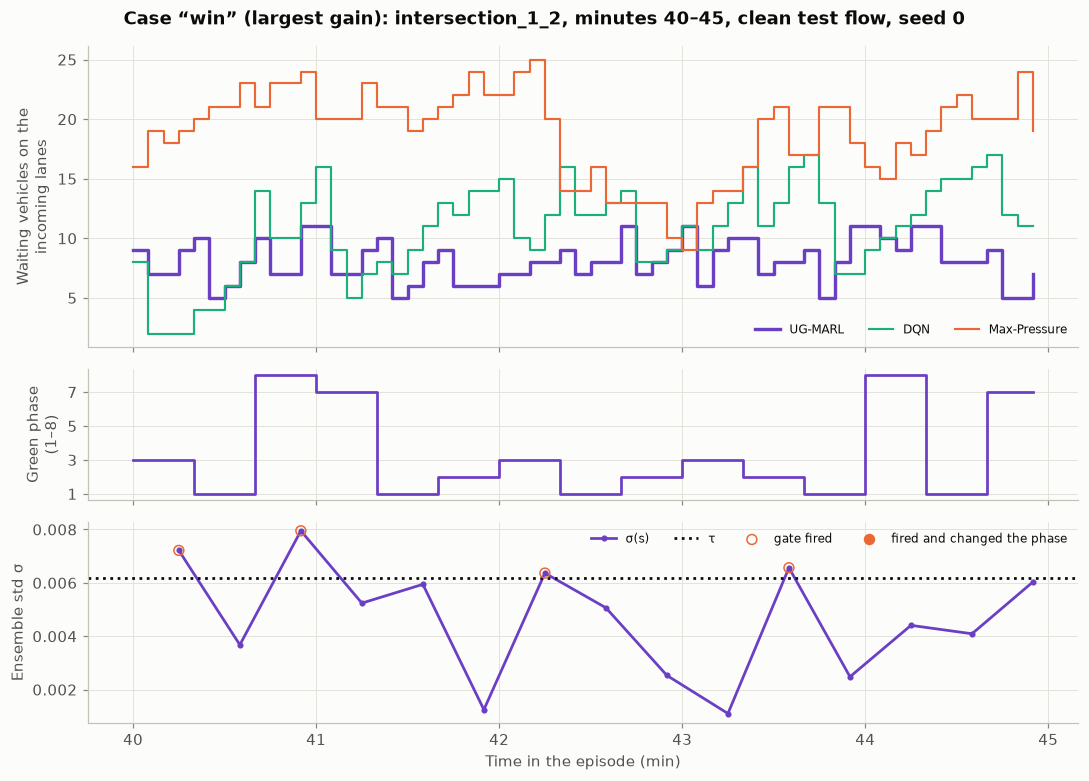

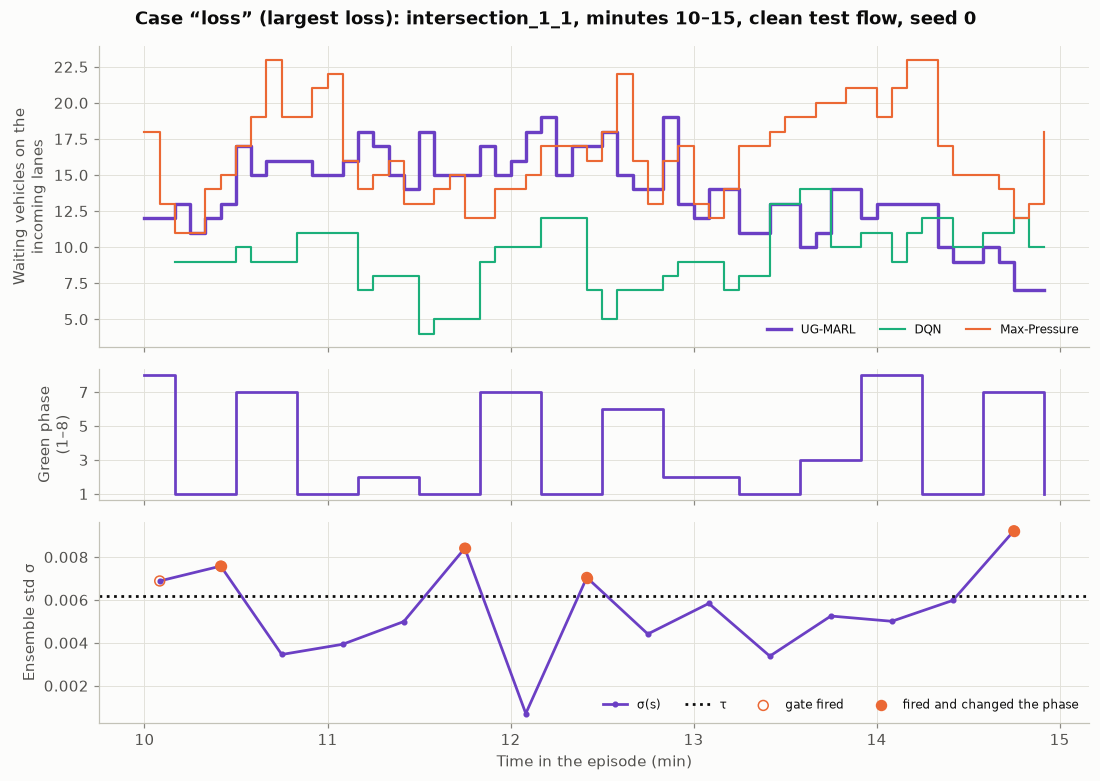

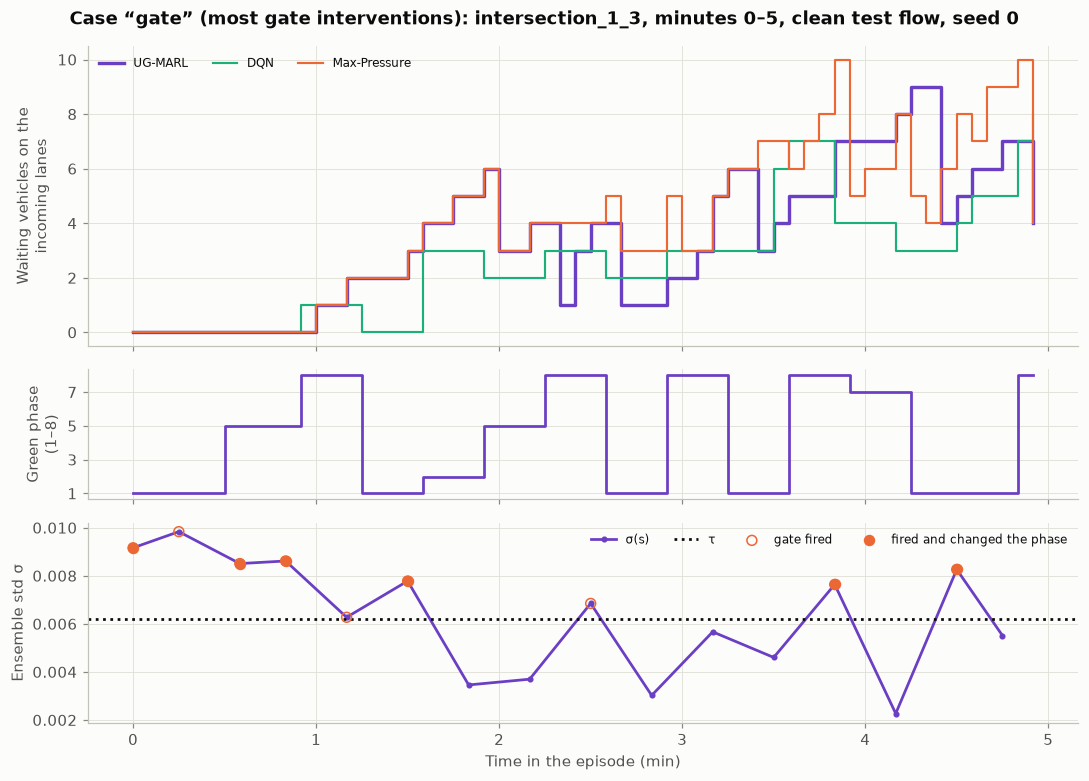

In [39]:
W = cfg["case_window_s"]
case_seed, cases = select_cases(test, PROPOSED, "dqn", "clean", W)
print("seed", case_seed)
display(pd.DataFrame(cases).T)
for kind, unit in cases.items():
    series, dec = case_inputs(test, [PROPOSED, *BASELINES], "clean", case_seed, unit, W)
    fig = fig_case(kind, unit, series, dec, W, case_seed, "clean", ctx.figures)

**Reading.** *Win* (1_2, minutes 40–45): UG-MARL holds a shorter queue than DQN through a busy
stretch; *loss* (1_1, minutes 10–15): DQN keeps the queue near 9 vehicles while UG-MARL sits
near 15, with four gate overrides in five minutes, each followed by a phase the learned policy
would not have chosen; *gate* (1_3, first five minutes): six overrides while the network is
filling and the inputs (near-empty lanes) are unlike most of the training data. The loss case
shows the mechanism of §4.1 in one place — σ hovering around τ at a corner intersection, the
fallback switching phases in and out. One seed, three windows: illustrations only.

## 6  Unstable decisions and spread over seeds

In [40]:
def stability_table(study: Study, models: Sequence[str], conditions: Sequence[str]) -> pd.DataFrame:
    """Per model × condition, mean over seeds: decisions, phase changes and flip-flops per
    episode, and their shares of all decisions (from the traces)."""
    rows = []
    for m in models:
        for c in conditions:
            t = study.each_seed(m, c, "trace", intersection_table)
            per = t.groupby("seed")[["decisions", "phase_changes", "flip_flops"]].sum()
            rows.append(
                {
                    "model": m,
                    "condition": c,
                    "decisions": per["decisions"].mean(),
                    "phase_changes": per["phase_changes"].mean(),
                    "flip_flops": per["flip_flops"].mean(),
                    "change_share": (per["phase_changes"] / per["decisions"]).mean(),
                    "flip_flop_share": (per["flip_flops"] / per["decisions"]).mean(),
                    "flip_flop_share_std": (per["flip_flops"] / per["decisions"]).std(ddof=1),
                }
            )
    return pd.DataFrame(rows)


def seed_spread(study: Study, models: Sequence[str], condition: str, metric: str) -> pd.DataFrame:
    """Per model: every seed's value plus min, max and range over seeds."""
    rows = []
    for m in models:
        v = study.values(m, condition, metric)
        rows.append(
            {
                "model": m,
                **{f"s{s}": x for s, x in zip(study.seeds, v, strict=True)},
                "min": min(v),
                "max": max(v),
                "range": max(v) - min(v),
            }
        )
    return pd.DataFrame(rows)


def fig_seed_spread(study: Study, models: Sequence[str], out=None) -> plt.Figure:
    apply_style()
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
    panels = [("avg_travel_time_s", "Average travel time (s)"),
              ("max_waiting_time_s", "Maximum per-vehicle wait (s)")]
    vals = []
    for ax, (metric, ylabel) in zip(axes, panels, strict=True):
        for k, m in enumerate(models):
            v = study.values(m, "clean", metric)
            ax.scatter([k] * len(v), v, color=CONTROLLER_COLOR[m], s=28, zorder=3,
                       marker="D" if m == "ugmarl-nogate" else "o")
            for s, x in zip(study.seeds, v, strict=True):
                ax.annotate(str(s), (k, x), xytext=(6, -3), textcoords="offset points",
                            fontsize=7, color=MUTED)
            vals.append(f"{short(m)} {metric.split('_')[0]} range {max(v) - min(v):.1f}")
        names = [short(m).replace("UG-MARL ", "") for m in models]
        ax.set_xticks(range(len(models)), names, rotation=20, ha="right")
        ax.set_ylabel(ylabel)
        ax.grid(axis="x", visible=False)
    fig.suptitle("Spread over the five training seeds, clean Jinan test flow", fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "seed_spread", "spread over training seeds",
        "Every seed's result on the clean Jinan test flow for the learned models (the number "
        "next to a point is the seed; seed s = the model trained with seed s). The y axes do "
        "not start at 0.",
        "; ".join(vals) + ".",
    )

condition,clean,noise0.2,surge1.5
model,,,
fixed_time,0,0,0
max_pressure,0.203,0.114,0.198
dqn,0.202,0.163,0.221
idqn,0.19,0.156,0.184
ugmarl,0.215,0.118,0.209
ugmarl-nogate,0.237,0.182,0.225
ugmarl-noattn,0.186,0.121,0.209
ugmarl-noens,0.211,0.173,0.208


condition,clean,noise0.2,surge1.5
model,,,
fixed_time,0.495,0.495,0.495
max_pressure,0.874,0.863,0.833
dqn,0.981,0.826,0.955
idqn,0.964,0.82,0.832
ugmarl,0.962,0.865,0.904
ugmarl-nogate,0.98,0.774,0.948
ugmarl-noattn,0.966,0.866,0.908
ugmarl-noens,0.976,0.732,0.888


,model,s0,s1,s2,s3,s4,min,max,range
0,dqn,291.3,292.5,292.5,292.9,291.9,291.3,292.9,1.6
1,idqn,307.6,309.1,309.1,308.3,305.6,305.6,309.1,3.5
2,ugmarl,295.3,295.1,296.6,296.2,293.8,293.8,296.6,2.8
3,ugmarl-nogate,295.9,293.9,296.3,294.6,294.2,293.9,296.3,2.4
4,ugmarl-noattn,294.4,293.3,294.3,295.8,293.3,293.3,295.8,2.6
5,ugmarl-noens,295.5,299.4,296.4,297,298.3,295.5,299.4,3.9


,model,s0,s1,s2,s3,s4,min,max,range
0,dqn,671,882,605,840,864,605,882,277
1,idqn,679,834,678,848,707,678,848,170
2,ugmarl,1052,1000,631,832,964,631,1052,421
3,ugmarl-nogate,1078,601,1053,927,893,601,1078,477
4,ugmarl-noattn,915,824,692,952,995,692,995,303
5,ugmarl-noens,696,577,615,654,1159,577,1159,582


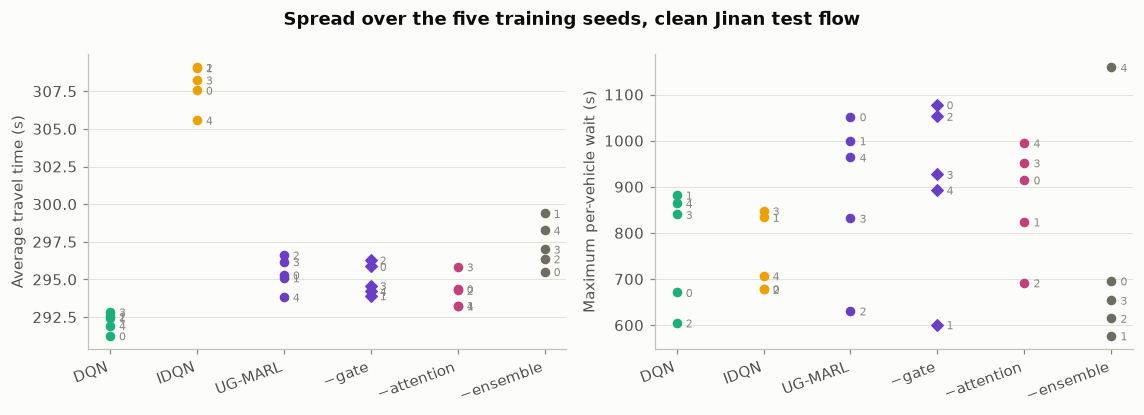

In [41]:
stab = stability_table(test, test.models, ["clean", "noise0.2", "surge1.5"])
display(show(stab.pivot(index="model", columns="condition", values="flip_flop_share").loc[test.models].round(3), "Flip-flops (A → B → A with B held for one decision) as a share of all decisions, mean over seeds"))
display(show(stab.pivot(index="model", columns="condition", values="change_share").loc[test.models].round(3), "Decisions that change the phase, share of all decisions"))
LEARNED = ["dqn", "idqn", *ABLATIONS]
display(show(seed_spread(test, LEARNED, "clean", "avg_travel_time_s").round(1), "Clean test travel time per seed (s)"))
display(show(seed_spread(test, LEARNED, "clean", "max_waiting_time_s").round(0), "Clean test maximum per-vehicle wait per seed (s)"))
fig = fig_seed_spread(test, LEARNED, ctx.figures)

**Reading.** *Flip-flops:* every adaptive controller changes phase on 83–98 % of its decisions
(8 phases, 15 s interval) and returns to the previous phase after a single interval on about
20 % of them. UG-MARL (21.5 %) is in the same range as DQN (20.2 %) and Max-Pressure (20.3 %);
the gate lowers it slightly relative to the same checkpoints without a gate (23.7 %). Under
noise UG-MARL's rate equals Max-Pressure's (11.8 vs 11.4 %). The policy is not more unstable
than its baselines. *Seeds:* clean travel time varies by 2.8 s across UG-MARL's five seeds
(DQN 1.6 s, IDQN 3.5 s, −ensemble 3.9 s) — the 3.2 s gap to DQN is of the size of the seed
range, though the CIs are separated. The maximum wait varies by 421 s across seeds (631–1052
s), which is why the clean part of H2 is "no difference": that metric is one vehicle.

## 7  Sensitivity: gate threshold τ (validation) and distribution shift (Hangzhou)

**τ sweep.** `scripts/tau_sweep.py` evaluated p = 50, 60, 70 on the validation flow *after* the
final evaluation (75 episodes); the other rows come from the calibration and the validation
robustness table. The reading rule was fixed before the runs. p\* = 80 and every `gate.json`
are unchanged.

In [42]:
def fig_tau_sensitivity(table: pd.DataFrame, p_star: float, out=None) -> plt.Figure:
    """``table``: rows ``p`` (number, ``ungated`` or ``max_pressure``), ``condition``,
    ``avg_travel_time_mean``, CI columns, ``fallback_rate_mean``
    (``docs/results/tau_sensitivity.csv``)."""
    apply_style()
    t = table.copy()
    num = t[pd.to_numeric(t["p"], errors="coerce").notna()].copy()
    num["p"] = num["p"].astype(float)
    conds = list(dict.fromkeys(t["condition"]))
    ramp = plt.get_cmap("viridis")(np.linspace(0.05, 0.9, len(conds)))
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13.0, 4.2))
    ps = sorted(num["p"].unique())
    xpos = {p: i + 1 for i, p in enumerate(ps)}
    xpos.update({"max_pressure": 0, "ungated": len(ps) + 1})
    ticks = ["MP\n(τ = 0)", *[f"{p:g}" for p in ps], "no gate\n(τ = ∞)"]
    for c, col in zip(conds, ramp, strict=True):
        g = t[t["condition"] == c]
        x = [xpos[float(p)] if str(p).replace(".", "").isdigit() else xpos[p] for p in g["p"]]
        o = np.argsort(x)
        x = np.asarray(x)[o]
        ax1.plot(x, g["avg_travel_time_mean"].to_numpy()[o], color=col, marker="o", label=cond(c))
        ax2.plot(x, g["fallback_rate_mean"].to_numpy()[o], color=col, marker="o")
    score = t.groupby("p", sort=False)["avg_travel_time_mean"].mean()
    xs = [xpos[float(p)] if str(p).replace(".", "").isdigit() else xpos[p] for p in score.index]
    o = np.argsort(xs)
    sx, sy = np.asarray(xs)[o], score.to_numpy()[o]
    gated = sx != xpos["ungated"]
    ax3.plot(sx[gated], sy[gated], color=INK, marker="o")
    for x, v in zip(sx[gated], sy[gated], strict=True):
        ax3.annotate(f"{v:.1f}", (x, v), xytext=(0, 7), textcoords="offset points",
                     ha="center", fontsize=8)
    if (~gated).any():
        ax3.annotate(f"{sy[~gated][0]:.1f} ↑\n(off scale)", (xpos["ungated"], sy[gated].max()),
                     ha="center", va="bottom", fontsize=8, color=INK_SECONDARY)
    ax3.set_ylim(sy[gated].min() - 2, sy[gated].max() + 4)
    for ax in (ax1, ax2, ax3):
        ax.axvline(xpos[float(p_star)], color=VIOLET, linestyle=":", linewidth=1.4)
        ax.set_xticks(range(len(ticks)), ticks, fontsize=8)
        ax.set_xlabel("Percentile p of clean validation σ used as τ")
    ax1.set_yscale("log")
    ax1.set_ylabel("Average travel time (s, log scale)")
    ax1.legend(fontsize=8)
    ax1.set_title("(a) Travel time per condition", fontsize=10)
    ax2.set_ylabel("Share of decisions handed to Max-Pressure")
    ax2.set_title("(b) Fallback rate", fontsize=10)
    ax3.set_ylabel("Mean over the five conditions (s)")
    ax3.set_title("(c) Calibration score", fontsize=10)
    fig.suptitle("Sensitivity to the gate threshold on the validation flow "
                 f"(dotted: p* = {p_star:g})", fontweight="bold")
    fig.tight_layout()
    return finish(
        fig, out, "tau_sensitivity", "sensitivity to the gate threshold τ (validation)",
        "UG-MARL on the Jinan validation flow with τ set to the p-th percentile of each "
        "seed-model's clean validation σ, from Max-Pressure (the gate always fires) to the "
        "ungated policy; mean over seeds 0–4. (a) travel time per detector condition, (b) "
        "fallback rate, (c) the calibration score (mean travel time over the five "
        "conditions). p = 50, 60, 70 were added after the final evaluation as a sensitivity "
        "check; nothing was re-selected (p* = 80).",
        "Score: " + ", ".join(f"p {p} = {v:.1f} s" for p, v in score.items()) + ".",
    )

,score,fallback
p,,
max_pressure,351.44,1
50.0,343.23,0.7
60.0,343.84,0.63
70.0,342.27,0.56
80.0,343.73,0.49
90.0,343.69,0.41
95.0,346.56,0.36
99.0,347.76,0.3
ungated,485.24,0


condition,clean,drop0.1,drop0.2,noise0.1,noise0.2
p,,,,,
max_pressure,326.1,322.8,321.7,371.7,414.9
50.0,305.6,308.9,311.8,372.2,417.6
60.0,304.5,307.8,312.4,374,420.5
70.0,302.5,307.2,311.7,374.1,416
80.0,302.3,306,310.6,376.5,423.4
90.0,301.8,306.1,311.2,380.8,418.6
95.0,302,305.8,310.8,389.6,424.7
99.0,302,306.5,311.4,395.1,423.9
ungated,301.8,306.1,310.3,599.2,908.8


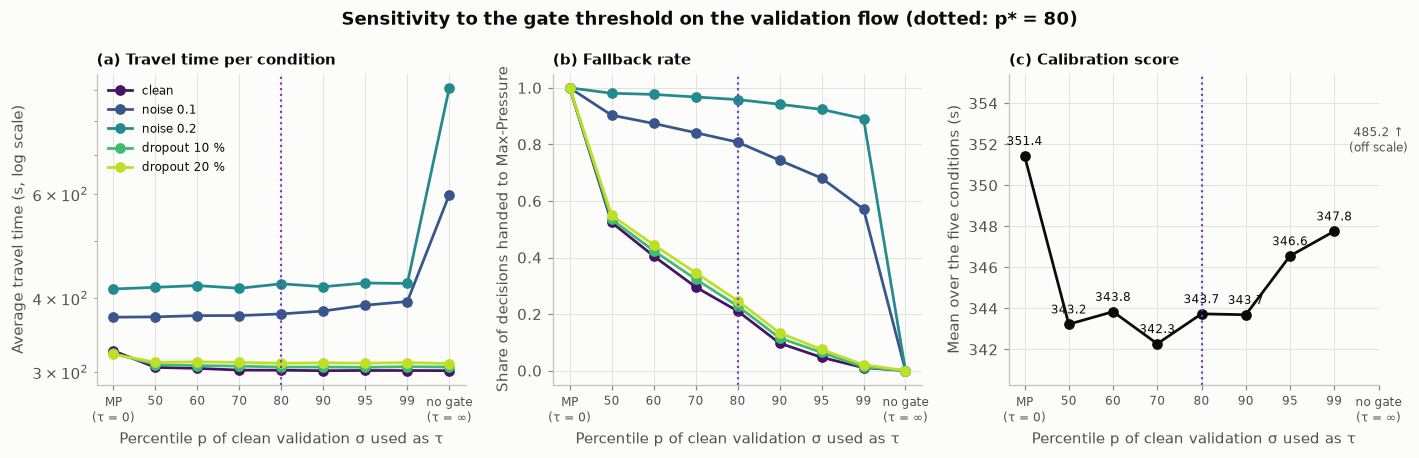

In [43]:
tau = ctx.table("tau_sensitivity")
if tau is None:
    display(Markdown("**Not run yet:** `python scripts/tau_sweep.py --search configs/search/tau_sensitivity.yaml`"))
else:
    display(show(tau.groupby("p", sort=False).agg(score=("avg_travel_time_mean", "mean"), fallback=("fallback_rate_mean", "mean")).round(2), "Calibration score = mean travel time over seeds × the five validation conditions (s)"))
    display(show(tau.pivot(index="p", columns="condition", values="avg_travel_time_mean").loc[list(dict.fromkeys(tau["p"]))].round(1), "Validation travel time per condition (s)"))
    fig = fig_tau_sensitivity(tau, 80, ctx.figures)

**Reading (rule fixed before the runs).** *Insensitive:* every p from 50 to 90 scores within
5 s of the locked p\* = 80 (342.3–343.8 s vs 343.7 s); only p ≥ 95 is 3–4 s worse and no gate
at all is 141 s worse. *Lower end binding:* p = 70 scores 1.5 s better than p\* = 80, more than
the 1 s tie tolerance, so by the rule the calibration grid's lower end was binding — had 70
been in the grid it would have been chosen. The difference is small and not monotone (p = 60
is 0.1 s worse than 80), well inside the seed spread of the noisy conditions (std 4–7 s).
The trade-off is visible per condition: lowering p costs on clean data (302.3 → 305.6 s from
p = 80 to 50) and gains under noise (376.5 → 372.2 s at noise 0.1), with Max-Pressure as the
limit. **Nothing is changed:** p\* = 80, the `gate.json` files and the test results stay.

**Distribution shift.** The held-out city, zero-shot (τ from Jinan validation).

In [44]:
def heldout_overview(study: Study, model: str, others: Sequence[str]) -> pd.DataFrame:
    """Per held-out flow: the gated model's fallback rate (overall, lowest and highest
    intersection), median σ / τ, and mean travel time / max wait of the model and ``others``."""
    rows = []
    for f in study.conditions:
        d = pd.concat([study.log(model, f, "decisions", s) for s in study.seeds])
        per = d.groupby("iid")["fallback"].mean()
        row = {
            "flow": f,
            "fallback": float(d["fallback"].mean()),
            "fallback_min_iid": float(per.min()),
            "fallback_max_iid": float(per.max()),
            "sigma_over_tau_median": float((d["sigma"] / d["tau"]).median()),
        }
        for m in [model, *others]:
            row[f"travel_{m}"] = study.stats(m, f, "avg_travel_time_s")["mean"]
            row[f"max_wait_{m}"] = study.stats(m, f, "max_waiting_time_s")["mean"]
        rows.append(row)
    return pd.DataFrame(rows)


def model_order(study: Study, models: Sequence[str], conditions: Sequence[str]) -> pd.DataFrame:
    """Models ordered by mean travel time (best first) in each condition."""
    out = {}
    for c in conditions:
        means = {m: study.stats(m, c, "avg_travel_time_s")["mean"] for m in models}
        out[c] = sorted(means, key=means.get)
    return pd.DataFrame(out, index=range(1, len(models) + 1)).rename_axis("rank")

,0,1,2
flow,real,real_5734,real_5816
fallback,0.25,0.4,0.37
fallback_min_iid,0.19,0.21,0.2
fallback_max_iid,0.35,0.92,0.72
sigma_over_tau_median,0.72,0.85,0.82
travel_ugmarl,347.32,466.4,416.32
max_wait_ugmarl,1170,3167.2,2449.2
travel_dqn,343.44,478.74,409.13
max_wait_dqn,877.4,2087.8,2015.8
travel_max_pressure,360.66,500.05,434.66


,Jinan test,real,real_5734,real_5816
rank,,,,
1,dqn,dqn,ugmarl,dqn
2,ugmarl,ugmarl,dqn,ugmarl
3,max_pressure,max_pressure,max_pressure,max_pressure
4,fixed_time,fixed_time,fixed_time,fixed_time


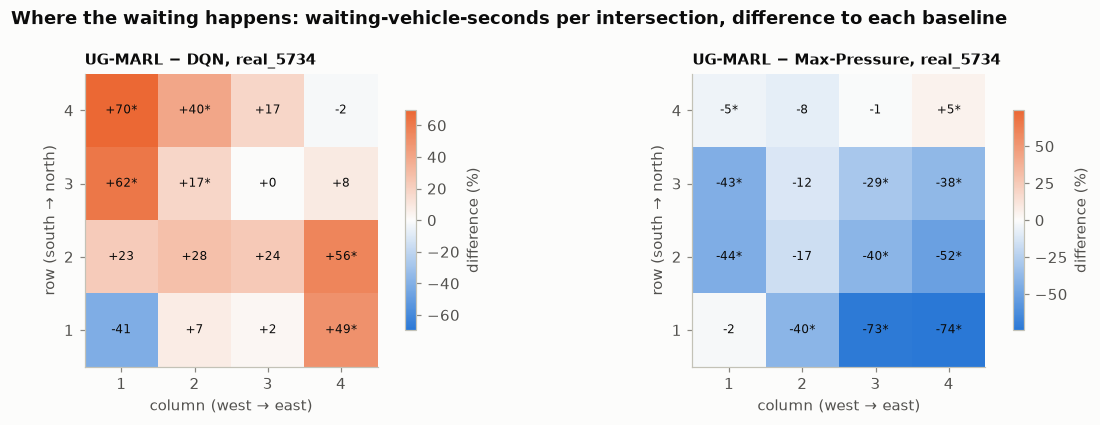

In [45]:
display(show(heldout_overview(held, PROPOSED, ["dqn", "max_pressure", PAIRED]).round(2).T, "Hangzhou per flow: UG-MARL's gate and travel time / max wait against DQN, Max-Pressure and −gate"))
order = pd.concat([model_order(test, [m for m in AGENTS if m in held.models], ["clean"]).rename(columns={"clean": "Jinan test"}),
                   model_order(held, [m for m in AGENTS if m in held.models], held.conditions)], axis=1)
display(show(order, "Model order by mean travel time (1 = best)"))
hi = {(b, f): comparison(held_frames[f], "intersections", ["iid"], "wait_veh_s", PROPOSED, b, f)
      for f in held.conditions[1:2] for b in BASELINES}
fig = fig_error_intersections(hi, PROPOSED, ctx.figures, name="error_intersections_heldout")

**Reading.** In the unseen city the gate fires on 25–40 % of decisions (20 % on Jinan clean):
the median σ is closer to τ (0.72–0.85 τ) but the inputs are not treated as wholly unfamiliar.
The firing is concentrated: on `real_5734` one intersection hands 92 % of its decisions to
Max-Pressure while the calmest hands over 21 %. Travel time: UG-MARL is level with DQN on all
flows (CIs overlap), nominally 12 s better on the most congested one (`real_5734`: 466 vs 479 s,
and 25 s better than its own ungated version), and the model order is the same as on Jinan except that UG-MARL and DQN
swap there. Maximum wait: UG-MARL is below Max-Pressure on every flow but above DQN, and on
`real_5734` it is as high as Max-Pressure's (3167 vs 3182 s) — the surge pattern again: heavy
fallback brings Max-Pressure's tail with it. The grid shows where waiting differs from each
baseline on that flow.

## 8  Tables written for the report, and the summary

In [46]:
def _md(df: pd.DataFrame, digits: int = 1) -> list[str]:
    def cell(v) -> str:
        if isinstance(v, (bool, np.bool_)):
            return "yes" if v else "no"
        if isinstance(v, (float, np.floating)):
            return "—" if np.isnan(v) else f"{v:.{digits}f}"
        return str(v)

    head = "| " + " | ".join(map(str, df.columns)) + " |"
    lines = [head, "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(cell(v) for v in r) + " |" for r in df.itertuples(index=False)]
    return lines


def write_error_report(path: str | Path, sections: Sequence[tuple[str, str, pd.DataFrame]],
                       intro: str) -> Path:
    """Write ``docs/results/error_analysis.md`` and one CSV per section next to it.
    ``sections``: (slug, heading + note, frame)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    lines = ["# Error analysis — Jinan test flow and Hangzhou (ROADMAP 8.4)", "", intro, ""]
    for slug, heading, frame in sections:
        frame.to_csv(path.with_name(f"{path.stem}_{slug}.csv"), index=False)
        title, _, note = heading.partition("\n")
        lines += [f"## {title}", ""]
        if note:
            lines += [note, ""]
        lines += [*_md(frame), "", f"CSV: `{path.stem}_{slug}.csv`", ""]
    path.write_text("\n".join(lines))
    return path

In [47]:
sections = [
    ("entry", "Vehicles blocked outside the network\nMean over seeds. The waiting-time metrics count waiting inside the network only.", entry),
    ("intersections", "Waiting-vehicle-seconds per intersection, UG-MARL − baseline\n`_a` = UG-MARL, `_b` = baseline; mean, 95 % CI and `clear` are over the per-seed differences.",
     stack_comparisons(ci).drop(columns=["n", "deterministic", "std"])),
    ("windows", "Travel time by 10-minute start window, UG-MARL − baseline (s)", stack_comparisons(cw).drop(columns=["n", "deterministic", "std"])),
    ("route_length", "Travel time by number of intersections on the route, UG-MARL − baseline (s)", stack_comparisons(cl).drop(columns=["n", "deterministic", "std"])),
    ("route_turns", "Travel time by route type, UG-MARL − baseline (s)", stack_comparisons(ct).drop(columns=["n", "deterministic", "std"])),
    ("gate_effect", "Queue change in the 60 s after a decision: gate changed the phase vs gate quiet\nSame intersection and 10-minute window; an association.", gate),
    ("surge_windows", "Surge ×1.5: time inside the network by entry window\nFrom the per-vehicle logs alone (no route join for the surge flow).", sw),
    ("approaches", "Fairness between approaches, clean test flow", approach_overview(test, AGENTS, "clean")),
    ("stability", "Phase changes and flip-flops", stab),
    ("seeds_travel", "Clean test travel time per seed (s)", seed_spread(test, LEARNED, "clean", "avg_travel_time_s")),
    ("seeds_max_wait", "Clean test maximum per-vehicle wait per seed (s)", seed_spread(test, LEARNED, "clean", "max_waiting_time_s")),
    ("heldout", "Hangzhou per flow", heldout_overview(held, PROPOSED, ["dqn", "max_pressure", PAIRED])),
    ("cases", "Representative cases (rule A7)\nSeed " + str(case_seed) + ", clean test flow.", pd.DataFrame(cases).T.reset_index(names="case")),
]
intro = ("Generated by `notebooks/03_error_analysis.ipynb` from the logs of the single Phase 7 pass (`results/final/`), seeds 0–4; "
         "nothing is simulated, fitted or selected. Differences are per-seed differences with a Student-t 95 % CI; "
         "`clear` = the CI excludes 0. Interpretation: report Ch. 4.")
out = write_error_report(ctx.tables / "error_analysis.md", sections, intro)
print("written:", out.relative_to(REPO_ROOT), "+", len(sections), "CSV files;", len(list(ctx.figures.glob("*.png"))), "figures in", ctx.figures.relative_to(REPO_ROOT))

written: docs/results/error_analysis.md + 13 CSV files; 18 figures in docs/figures/results


### Summary — what the evidence shows

1. **Where UG-MARL loses to DQN (clean, 3.2 s):** everywhere a little — more waiting at all 12
   intersections (clear at 4), in every 10-minute window, growing with route length and
   carried by turning trips. The gate is not the cause (gate on vs off: level), and all four
   UG-MARL variants are 2–5 s behind DQN, so the deficit is common to the UG-MARL network
   family and its hyperparameters (inherited from the DQN search, not retuned), not to one
   component. The runs available cannot separate it further.
2. **Where it wins:** against Max-Pressure on clean data at every intersection (17–40 % less
   waiting); against every ungated learned policy under detector noise (which leave 11–14 %
   of vehicles outside the network at noise 0.2 — a failure the max-wait metric does not see).
3. **Where it ties:** Max-Pressure under noise (level at 11 of 12 intersections; slightly worse
   on long, straight trips).
4. **Where the gate costs:** demand surge and the heaviest Hangzhou flow. Travel time is fine,
   but once the fallback rate passes ~60 % the longest waits approach Max-Pressure's.
5. **Gate threshold:** insensitive between p = 50 and 90; p = 70 would have scored 1.5 s
   better on validation. Not changed.
6. **Attention:** weights rank neighbour influence (replacement test), but the influence is
   about one seventh of the intersection's own observation; no travel-time benefit (H3).
7. **Stability:** flip-flop rate and seed spread are in the range of the baselines.

**What remains uncertain:** five seeds; one city family and grid networks only; σ over three
heads is a coarse signal that detects unfamiliar inputs rather than wrong actions; the
per-intersection results are waiting, not delay; validation was reused for checkpoint, (K, d)
and p\*. Full discussion: report Ch. 4.